# Entrega 3 (corregida) · Modelado del ganador de partidos de CS2
**Ciencia de Datos · UTN FRM · Comisión 5K10 · Grupo 07**

**Integrantes:** Berducci Nicolás · Genaulaz Martin · Yanardi Tomás · Yanardi Juan Cruz · Gallardo Federico · León Mario.

Queremos predecir, **antes de que empiece una serie**, cuál de los dos equipos la va a ganar. Cada fila es una serie completa, no un mapa ni un jugador. `target_team_a_won = 1` si ganó A y `0` si ganó B. A es el equipo con menor ID: no es local ni favorito.

El notebook corre completo de arriba hacia abajo, con `SEMILLA = 42` definida al principio y pasada a todo lo que la acepta. Es la base de la aplicación de la Entrega 4: `build_app.py` usa las mismas funciones (`cs2_modelo.py`) y el mismo modelo, y la última sección comprueba que lo que muestra la aplicación coincide con lo que da este notebook.

### Qué corregimos desde la versión presentada

| Lo que nos marcaron | Qué hicimos | Dónde |
|---|---|---|
| Comparar la logística con otros modelos **con su propio ajuste de hiperparámetros**, no solo con una configuración fija. | Las cuatro familias —regresión logística, **árbol de decisión** (nuevo), random forest y gradient boosting— pasan cada una por su grilla completa, con las mismas columnas y los mismos folds. Recién después aplicamos la regla de elección. La logística se sostiene, ahora contra rivales ajustados. Mostramos además cómo rinden los cuatro en el test, una vez congelado todo. | Secciones 7, 9.1 y 11 |
| Detallar más **dónde y por qué falla** el modelo, con gráficos. | La sección 11.2 creció: errores por confianza del modelo, por diferencia de Elo, «sorpresas», por tipo de partido, a lo largo del tiempo, el perfil de los errores con mucha confianza, si los otros modelos fallan en las mismas series, la calibración de las probabilidades y casos concretos. | Sección 11.2 |

## 0. Qué retomamos y qué cambia desde la Entrega 2

### Lo que nos corrigieron

**El dataset.** En la Entrega 2 nuestro dataset no tenía features agregadas: las columnas eran las mismas del Bronze, sin ningún cálculo. Lo que correspondía era un Silver mucho más trabajado, casi «goldificado», con variables calculadas a partir de los partidos anteriores de cada equipo. Corregimos el DAG. Ahora cada fila es una serie y sus estadísticas se calculan solo con partidos que terminaron antes de su inicio: Elo, winrates de 5, 10 y 20 partidos, KD, KDA, rating, ADR, mapas y rondas ganadas, rendimiento en el mismo formato y en el mismo tier, días de descanso, actividad en los últimos 7 y 30 días, estabilidad de la alineación, enfrentamientos directos (H2H) y ranking previo, además de la diferencia A−B de cada una. Con estas correcciones el dataset quedó en **43.719 partidos y 113 columnas**.

**La matriz de correlación.** La agregamos a pedido del profesor para detectar columnas redundantes. Usamos la correlación de Spearman: cuando dos columnas tenían |ρ| ≥ 0,8, nos quedamos con la que mejor separaba al target y sacamos la otra.

### De 113 a 27 columnas

Después de revisar la matriz de correlación y las hipótesis de la Entrega 2, nos quedaron **27 columnas**:

| Paso | Qué sale | Salen | Quedan |
|---|---|---|---|
| Silver corregido | — | — | 113 |
| No son predictores | 12 de identificación y contexto (IDs, nombres, fecha, torneo, etapa, versión del juego), el objetivo, 3 del resultado del propio partido (fin y mapas ganados: serían fuga) y 2 códigos de país | 18 | 95 |
| Calidad de datos | Familia KAST: tiene valores cero en partidos con kills | 5 | 90 |
| Diferencias A−B | Valores individuales de A y B, ya resumidos en su diferencia | 32 | 58 |
| Hipótesis | H1, descanso (3); H3, winrate de 10 (1); H4, antigüedad del ranking (1) | 5 | 53 |
| Columnas idénticas | Contadores exactamente iguales a otro contador | 6 | 47 |
| Matriz de correlación | 6 contadores que son fórmula directa de `matches_prior` y 14 columnas con \|ρ\| ≥ 0,8 | 20 | 27 |

### Cierre de la Entrega 2: las 27 columnas que quedaron

Son 25 numéricas más `bo_type` y `tier`. A los dos `matches_prior` les aplicamos `log1p`, por su asimetría. Con estas 27 columnas arranca el modelado.

| # | Columna | Qué mide |
|---|---|---|
| 1 | `bo_type` | Formato de la serie: BO1, BO2, BO3 o BO5. |
| 2 | `tier` | Nivel del torneo según Bo3.gg: s, a, b, c o d. |
| 3 | `elo_advantage_a` | Elo de A menos Elo de B, antes del partido. |
| 4 | `ranking_score_advantage_a` | Puntaje de ranking de A menos el de B, en el último ranking anterior al partido. |
| 5 | `round_winrate_last20_advantage_a` | % de rondas ganadas en los últimos 20 partidos, A menos B. |
| 6 | `form_last5_advantage_a` | % de victorias en los últimos 5 partidos, A menos B. |
| 7 | `same_bo_winrate_last20_advantage_a` | % de victorias en partidos del mismo formato (dentro de los últimos 20), A menos B. |
| 8 | `same_tier_winrate_last20_advantage_a` | % de victorias en partidos del mismo tier (dentro de los últimos 20), A menos B. |
| 9 | `lineup_stability_last5_advantage_a` | Cuánto se mantuvo la alineación en los últimos 5 partidos (de 0 a 1), A menos B. |
| 10 | `h2h_team_a_winrate_last5` | % de victorias de A en los últimos 5 cruces contra B. |
| 11 | `h2h_last5_count` | Cuántos cruces previos entre los dos se usaron (de 0 a 5). |
| 12 | `team_a_matches_prior` | Partidos anteriores registrados de A (entra con `log1p`). |
| 13 | `team_b_matches_prior` | Partidos anteriores registrados de B (entra con `log1p`). |
| 14 | `team_a_form_trend_5v5` | Tendencia de A: % de victorias de los últimos 5 menos el de los 5 anteriores. |
| 15 | `team_b_form_trend_5v5` | Tendencia de B: % de victorias de los últimos 5 menos el de los 5 anteriores. |
| 16 | `team_a_matches_last7d` | Partidos que jugó A en los últimos 7 días. |
| 17 | `team_b_matches_last7d` | Partidos que jugó B en los últimos 7 días. |
| 18 | `team_a_matches_last30d` | Partidos que jugó A en los últimos 30 días. |
| 19 | `team_b_matches_last30d` | Partidos que jugó B en los últimos 30 días. |
| 20 | `team_a_kda_last20_count` | Partidos de A con KDA válido dentro de los últimos 20. |
| 21 | `team_b_kda_last20_count` | Partidos de B con KDA válido dentro de los últimos 20. |
| 22 | `team_a_same_bo_winrate_last20_count` | Partidos de A del mismo formato dentro de los últimos 20. |
| 23 | `team_b_same_bo_winrate_last20_count` | Partidos de B del mismo formato dentro de los últimos 20. |
| 24 | `team_a_same_tier_winrate_last20_count` | Partidos de A del mismo tier dentro de los últimos 20. |
| 25 | `team_b_same_tier_winrate_last20_count` | Partidos de B del mismo tier dentro de los últimos 20. |
| 26 | `team_a_lineup_stability_last5_count` | Comparaciones de alineación disponibles para A (de 0 a 4). |
| 27 | `team_b_lineup_stability_last5_count` | Comparaciones de alineación disponibles para B (de 0 a 4). |

## 1. Configuración y funciones

Las funciones que usamos en todo el notebook (`armar`, `medir`, `tabla_de`, la validación temporal y las auditorías) son las de la Entrega 3, sin cambios, y ahora viven en **`app/cs2_modelo.py`** del repositorio. Ahí también están la semilla, el corte del test, las columnas y las grillas. `build_app.py` importa el mismo archivo: así la aplicación no puede usar otra configuración que la de este notebook.

**En Colab:** subí `cs2_modelo.py` y `graficos.py` junto al notebook (o cloná el repositorio); el CSV se baja solo del Drive si no está.

In [1]:
import platform, importlib.util, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import altair as alt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
                             brier_score_loss, log_loss)
from sklearn.inspection import permutation_importance

# Busca cs2_modelo.py: en la carpeta actual, en app/ o un nivel arriba (Colab: subirlo junto al notebook).
RAIZ = next((d for d in [Path.cwd(), Path.cwd() / 'app', Path.cwd().parent, Path.cwd().parent / 'app']
             if (d / 'cs2_modelo.py').is_file()), None)
assert RAIZ is not None, 'Falta cs2_modelo.py: está en app/ del repositorio (en Colab, subirlo junto al notebook).'
sys.path.insert(0, str(RAIZ))
import cs2_modelo as cm
from cs2_modelo import (SEMILLA, N_SPLITS, N_JOBS, CORTE_TEST, UMBRAL, SCORING, COLUMNAS_E2, EXTRA,
                        FAMILIAS, GRILLAS, ORDEN_SIMPLICIDAD, armar, medir, tabla_de, metricas)
import graficos as graf

np.random.seed(SEMILLA)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110, 'font.size': 10})
print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| altair', alt.__version__)

python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | altair 5.5.0


## 2. Carga del Silver

Usamos la misma extracción de la Entrega 2 (`20261016T021804Z__3779b1d9`, publicada por el DAG el 16/10/2026). Verificamos su huella (SHA-256) para asegurarnos de que es exactamente el mismo archivo, y controlamos filas, columnas, clave y fechas antes de modelar.

In [2]:
ARCHIVO = cm.ruta_csv()          # datos/matches_latest.csv o la salida del DAG
if not ARCHIVO.is_file() and 'google.colab' in sys.modules:
    if importlib.util.find_spec('gdown') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
    import gdown
    ARCHIVO.parent.mkdir(exist_ok=True)
    gdown.download(id=cm.DRIVE_ID, output=str(ARCHIVO), quiet=False)

df = cm.cargar(ARCHIVO)          # verifica huella, clave, objetivo y fechas, y ordena en el tiempo
assert df.shape == (43719, 113)
print(f'{len(df):,} partidos y {df.shape[1]} columnas, del {df.start_at_utc.min():%d/%m/%Y} al {df.start_at_utc.max():%d/%m/%Y}.')
print('Partidos sin hora de finalización:', df.end_at_utc.isna().sum())

43,719 partidos y 113 columnas, del 02/10/2023 al 15/10/2026.
Partidos sin hora de finalización: 4


## 3. Control de las variables calculadas

Antes de usar las columnas del Silver comprobamos dos cosas:

1. **Las restas.** Cada diferencia `_advantage_a` tiene que ser igual a la columna de A menos la de B (en el puesto de ranking, B menos A, porque menor es mejor).
2. **El historial.** Recalculamos desde cero, solo con los resultados, el Elo, los winrates de 5, 10 y 20, la tendencia, los días de descanso y el H2H. Para cada partido usamos únicamente series que terminaron **antes** de su inicio, y comparamos con lo que trae el Silver.

Las estadísticas mecánicas (KDA, rondas, alineaciones) no se pueden recalcular desde este CSV, porque necesitan el detalle del Bronze.

In [3]:
tabla_derivadas = cm.auditar_derivadas(df)
display(tabla_derivadas)
tabla_historia = cm.auditar_historia_resultados(df)
display(tabla_historia)
assert tabla_derivadas['diferencias'].sum() == 0 and tabla_historia['diferencias'].sum() == 0

,derivada,fórmula,filas verificadas,diferencias
0,elo_advantage_a,team_a_elo - team_b_elo,43719,0
1,winrate_last10_advantage_a,team_a_winrate_last10 - team_b_winrate_last10,43719,0
2,winrate_last20_advantage_a,team_a_winrate_last20 - team_b_winrate_last20,43719,0
3,form_last5_advantage_a,team_a_form_last5 - team_b_form_last5,43719,0
4,kda_last20_advantage_a,team_a_kda_last20 - team_b_kda_last20,43719,0
5,kd_last20_advantage_a,team_a_kd_last20 - team_b_kd_last20,43719,0
6,rating_last20_advantage_a,team_a_rating_last20 - team_b_rating_last20,43719,0
7,adr_last20_advantage_a,team_a_adr_last20 - team_b_adr_last20,43719,0
8,map_winrate_last20_advantage_a,team_a_map_winrate_last20 - team_b_map_winrate_last20,43719,0
9,round_winrate_last20_advantage_a,team_a_round_winrate_last20 - team_b_round_winrate_last20,43719,0


,columna,diferencias,máximo error absoluto
0,team_a_matches_prior,0,0.000000e+00
1,team_a_elo,0,4.547474e-13
2,team_a_form_last5,0,0.000000e+00
3,team_a_form_last5_count,0,0.000000e+00
4,team_a_winrate_last10,0,5.551115e-17
5,team_a_winrate_last10_count,0,0.000000e+00
6,team_a_winrate_last20,0,1.110223e-16
7,team_a_winrate_last20_count,0,0.000000e+00
8,team_a_form_trend_5v5,0,5.551115e-17
9,team_a_rest_days,0,1.136868e-13


**Conclusión:** las 17 restas coinciden en las 43.719 filas, y el historial recalculado coincide en todas las columnas: 0 diferencias. Los errores máximos que aparecen son de redondeo, del orden de 10⁻¹³. Esto nos dice dos cosas:

1. Podemos usar las diferencias del Silver tal cual, sin recalcularlas.
2. El Elo y los winrates de cada partido se arman solo con resultados anteriores. No traen escondido el resultado del partido que queremos predecir.

## 4. Métrica y reglas, fijadas antes del primer modelo

**Métrica principal: accuracy**, el porcentaje de series acertadas. Elegimos esta y no F1 macro por tres motivos:

- **Las clases están casi parejas.** A gana el 53,6 % de las series y B el 46,4 %. La consigna advierte que la accuracy «esconde a la clase chica» cuando las clases están desparejas, y acá no hay clase chica.
- **Ningún error es más caro.** A es simplemente el equipo con menor ID: equivocarse a favor de A o a favor de B cuesta lo mismo.
- **Se lee directo:** «acertamos tantas series de cada 100».

Como control mostramos también el F1 macro y el recall de cada clase, para comprobar que el modelo no se olvide de B.

**Reglas que fijamos antes de ver resultados:**

- Todos los modelos se comparan con las mismas columnas y los mismos folds, con media y desvío.
- **Cada familia se compara con su mejor combinación de hiperparámetros**, elegida con su propia grilla sobre esos mismos folds (corrección de esta versión).
- Si un modelo más complejo no le gana a la logística por más de un desvío, nos quedamos con la logística. El orden de simplicidad es: logística, árbol, random forest, gradient boosting.
- En los experimentos de columnas, entre las variantes que empatan con la mejor (a menos de un desvío), elegimos la que tiene menos columnas.
- En cada grilla nos quedamos con la combinación de mayor accuracy media.
- El umbral de decisión queda en 0,50.
- El test no se usa para elegir nada: lo miramos una sola vez, al final.

## 5. Test reservado y validación cruzada temporal

Nuestras filas están ordenadas en el tiempo y queremos predecir partidos futuros. Por eso partimos por fecha: es la fila «en el tiempo» de la tabla de la consigna (`TimeSeriesSplit`).

- **Test:** todas las series que empiezan desde el 01/03/2026, el mismo corte de la Entrega 2. No se toca hasta la sección 11.
- **Entrenamiento:** las series que empezaron **y terminaron** antes del corte.
- **Purgados:** las que empezaron antes del corte pero no consta que hayan terminado antes. El 01/03 su resultado todavía no se conocía, así que no se pueden usar para entrenar; tampoco son test. Son 2 de 43.719 y no cambian ningún número: es para no entrenar con un resultado que todavía no existía.

Dentro del entrenamiento armamos 5 folds con `TimeSeriesSplit` sobre los días del calendario. Cada fold entrena con todo lo anterior y valida con el bloque siguiente, de unos 5 meses, con la misma purga.

No agrupamos por equipo. Queremos predecir partidos futuros de equipos que ya conocemos, así que un mismo equipo puede estar en entrenamiento y en validación. Lo que controlamos es el tiempo: nunca se entrena con partidos posteriores a los que se validan.

In [4]:
train, test, purgados = cm.separar(df)
assert not set(train.match_id) & set(test.match_id)
cv, tabla_folds = cm.construir_cv_temporal(train, N_SPLITS)
display(pd.DataFrame({'conjunto': ['entrenamiento', 'test', 'purgados'],
                      'series': [len(train), len(test), len(purgados)]}))
display(purgados)
display(tabla_folds)

,conjunto,series
0,entrenamiento,34898
1,test,8819
2,purgados,2


,match_id,start_at_utc,end_at_utc
28638,100557,2025-09-26 14:30:00+00:00,NaT
34850,112164,2026-02-28 05:54:15+00:00,2026-03-01 07:53:15+00:00


,fold,train desde,train hasta,validación desde,validación hasta (excl.),n train,n validación,purgados,% A train,% A validación
0,1,2023-10-02 21:00:00+00:00,2024-02-29 21:00:00+00:00,2024-03-01 00:00:00+00:00,2024-07-25 00:00:00+00:00,5191,6036,2,54.016567,52.833002
1,2,2023-10-02 21:00:00+00:00,2024-07-24 22:00:00+00:00,2024-07-25 00:00:00+00:00,2024-12-18 00:00:00+00:00,11221,6914,8,53.364228,52.386462
2,3,2023-10-02 21:00:00+00:00,2024-12-17 20:00:00+00:00,2024-12-18 00:00:00+00:00,2025-05-13 00:00:00+00:00,18141,5961,2,52.995976,53.497735
3,4,2023-10-02 21:00:00+00:00,2025-05-12 19:00:00+00:00,2025-05-13 00:00:00+00:00,2025-10-06 00:00:00+00:00,24101,4971,3,53.126426,53.952927
4,5,2023-10-02 21:00:00+00:00,2025-10-05 21:30:00+00:00,2025-10-06 00:00:00+00:00,2026-03-01 00:00:00+00:00,29071,5823,4,53.269581,53.666495


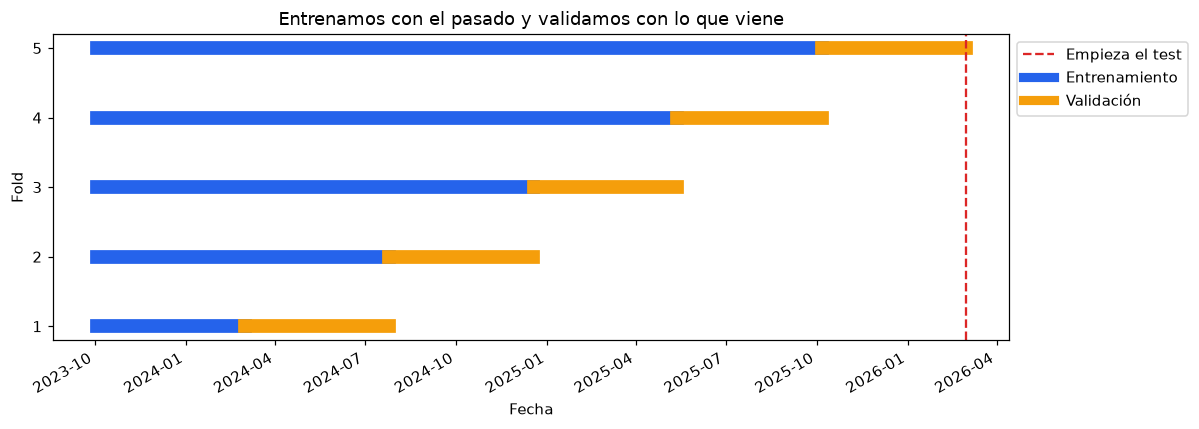

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
for k, (e, v) in enumerate(cv, 1):
    ax.plot([train.start_at_utc.iloc[e].min(), train.start_at_utc.iloc[e].max()], [k, k], lw=9, color='#2563eb')
    ax.plot([train.start_at_utc.iloc[v].min(), train.start_at_utc.iloc[v].max()], [k, k], lw=9, color='#f59e0b')
ax.axvline(CORTE_TEST, color='#dc2626', linestyle='--', label='Empieza el test')
ax.plot([], [], color='#2563eb', lw=6, label='Entrenamiento')
ax.plot([], [], color='#f59e0b', lw=6, label='Validación')
ax.set(yticks=range(1, N_SPLITS + 1), ylabel='Fold', xlabel='Fecha', title='Entrenamos con el pasado y validamos con lo que viene')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 6. Preparación dentro del pipeline

Todo lo que se le hace a los datos está dentro del pipeline. Así se vuelve a aprender en cada fold sin mirar la validación:

- **Numéricas:** imputamos con la mediana, agregamos un indicador de dato faltante y escalamos. Un faltante no es un cero: casi siempre significa que el equipo tenía menos de 5 partidos previos.
- **`matches_prior`:** `log1p` (decidido en la Entrega 2 por la asimetría) y escalado.
- **`bo_type` y `tier`:** one-hot. BO3 es un formato, no «tres veces BO1».

Usamos directamente las diferencias A−B que trae el Silver. En la sección 3 comprobamos que están bien calculadas, y una resta entre dos valores de la misma fila no aprende nada del resto de los datos, así que no genera fuga.

**La columna extra.** Además de las 27, X incluye `winrate_last20_advantage_a`, pero **no entra al modelo base**: solo la usamos en dos experimentos de la sección 8. La Entrega 2 la sacó por la correlación (es casi igual al winrate de rondas, que separaba mejor), pero tiene datos en más partidos: 82 % contra 74 %. Queremos ver si esa cobertura extra sirve.

In [6]:
assert len(set(COLUMNAS_E2)) == 27
X_train = train[COLUMNAS_E2 + [EXTRA]]
y_train = train.target_team_a_won
X_test = test[COLUMNAS_E2 + [EXTRA]]
y_test = test.target_team_a_won

clases = y_train.value_counts().sort_index().rename(index={0: 'gana B', 1: 'gana A'}).to_frame('series')
clases['%'] = (100 * clases.series / len(y_train)).round(1)
display(clases)
display(armar(LogisticRegression(max_iter=5000, random_state=SEMILLA), COLUMNAS_E2))

,series,%
target_team_a_won,,
gana B,16287,46.7
gana A,18611,53.3


Pipeline(steps=[('preparar',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['elo_advantage_a',
                                                   'ranking_score_advantage_a',
                                                   'round_winrate_last20_advantage_a',
                                                   'form_last5_advantage_a',
                                                   'same_bo_winrate_last20_advantage_...
                                                   'team_b_lineup_stability_last5_count']),
                                                 ('historia',
                                                  Pipeline(steps=[('log1p',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['team_a_matches_prior',
                                                   'team_b_matches_prior']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['bo_type', 'tier'])])),
                ('clasificador',
                 LogisticRegression(max_iter=5000, random_state=42))])

## 7. El piso y cuatro familias, cada una con su grilla

**Esta es la sección que corregimos.** En la versión anterior comparamos la logística contra un random forest y un gradient boosting con una sola configuración cada uno, elegida a mano. Eso no es justo para los árboles: quizás con otros hiperparámetros le ganaban. Ahora **cada familia tiene su propia búsqueda** (`GridSearchCV`) sobre los mismos 5 folds temporales y las mismas 27 columnas, y comparamos la mejor combinación de cada una.

| Familia | Qué es | Qué probamos en la grilla | Combinaciones |
|---|---|---|---|
| **Piso** | `DummyClassifier(most_frequent)`: dice siempre «gana A». | — | 1 |
| **Regresión logística** | Una suma ponderada de las columnas pasada por una sigmoide. | `C` (cuánto se frenan los coeficientes) y `class_weight`. | 8 |
| **Árbol de decisión** (nuevo) | Preguntas sí/no encadenadas sobre las columnas. | `max_depth` (cuántas preguntas seguidas), `min_samples_leaf` (cuántas series como mínimo en cada hoja) y `class_weight`. | 36 |
| **Random forest** | 200 árboles, cada uno con una muestra distinta, que votan. | `max_depth`, `min_samples_leaf` y `class_weight`. | 12 |
| **Gradient boosting** | Árboles chicos en serie, cada uno corrige los errores del anterior. | `learning_rate`, `max_iter` (cuántos árboles), `max_leaf_nodes` (tamaño de cada árbol) y `class_weight`. | 24 |

Todas las grillas reajustan el pipeline completo dentro de cada fold, así que la imputación y el escalado nunca miran la validación. Mostramos la accuracy de entrenamiento solo para ver cuánto memoriza cada modelo; no se elige con ella.

In [7]:
busquedas, grillas_completas = {}, {}
for nombre in ORDEN_SIMPLICIDAD:
    busquedas[nombre] = GridSearchCV(armar(FAMILIAS[nombre], COLUMNAS_E2), GRILLAS[nombre], scoring=SCORING,
                                     refit='accuracy', cv=cv, n_jobs=N_JOBS, return_train_score=True,
                                     error_score='raise').fit(X_train, y_train)
    grillas_completas[nombre] = tabla_de(busquedas[nombre])
    print(f'{nombre}: {len(grillas_completas[nombre])} combinaciones · ganadora {busquedas[nombre].best_params_}')

regresión logística: 8 combinaciones · ganadora {'clasificador__C': 1.0, 'clasificador__class_weight': None}


árbol de decisión: 36 combinaciones · ganadora {'clasificador__class_weight': 'balanced', 'clasificador__max_depth': 3, 'clasificador__min_samples_leaf': 50}


random forest: 12 combinaciones · ganadora {'clasificador__class_weight': None, 'clasificador__max_depth': 14, 'clasificador__min_samples_leaf': 50}


gradient boosting: 24 combinaciones · ganadora {'clasificador__class_weight': None, 'clasificador__learning_rate': 0.03, 'clasificador__max_iter': 100, 'clasificador__max_leaf_nodes': 7}


### 7.1 Las grillas completas

Cada tabla tiene todas las combinaciones probadas, ordenadas por accuracy media en validación, con su desvío entre folds.

**Regresión logística**

In [8]:
display(grillas_completas['regresión logística'].round(4).reset_index(drop=True))

,C,class_weight,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
0,1.00,None,0.6304,0.0082,0.6252,0.6224,0.7260,0.5215,1
1,0.10,None,0.6303,0.0080,0.6253,0.6223,0.7261,0.5213,2
2,10.00,None,0.6301,0.0081,0.6253,0.6222,0.7257,0.5214,3
3,0.01,None,0.6301,0.0077,0.6249,0.6218,0.7284,0.5183,4
4,0.01,balanced,0.6297,0.0051,0.6205,0.6280,0.6520,0.6044,5
5,0.10,balanced,0.6296,0.0053,0.6210,0.6279,0.6509,0.6053,6
6,1.00,balanced,0.6293,0.0054,0.6210,0.6276,0.6506,0.6050,7
7,10.00,balanced,0.6291,0.0056,0.6207,0.6275,0.6504,0.6048,8


**Árbol de decisión**

In [9]:
display(grillas_completas['árbol de decisión'].round(4).reset_index(drop=True))

,class_weight,max_depth,min_samples_leaf,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
0,balanced,3,50,0.6237,0.0097,0.6128,0.6170,0.7053,0.5305,1
1,balanced,3,200,0.6236,0.0102,0.6122,0.6170,0.7050,0.5307,2
2,balanced,3,1,0.6234,0.0098,0.6130,0.6167,0.7054,0.5299,3
3,None,3,50,0.6226,0.0098,0.6135,0.6169,0.6922,0.5435,4
4,None,3,200,0.6225,0.0103,0.6128,0.6169,0.6919,0.5437,5
5,None,3,1,0.6223,0.0099,0.6136,0.6166,0.6923,0.5428,6
6,None,8,200,0.6217,0.0066,0.6313,0.6167,0.6857,0.5484,7
7,None,10,200,0.6214,0.0066,0.6327,0.6158,0.6937,0.5389,8
8,None,14,200,0.6214,0.0066,0.6327,0.6158,0.6937,0.5389,8
9,None,4,200,0.6208,0.0097,0.6174,0.6102,0.7322,0.4931,10


**Random forest**

In [10]:
display(grillas_completas['random forest'].round(4).reset_index(drop=True))

,class_weight,max_depth,min_samples_leaf,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
0,None,14,50,0.6336,0.0081,0.6635,0.6260,0.7268,0.5275,1
1,None,10,50,0.6327,0.0075,0.6567,0.6245,0.7312,0.5205,2
2,None,14,10,0.6327,0.0084,0.7620,0.6254,0.7232,0.5297,3
3,balanced,10,10,0.6324,0.0073,0.7035,0.6302,0.6642,0.5961,4
4,None,10,10,0.6320,0.0077,0.7036,0.6236,0.7312,0.5189,5
5,balanced,6,50,0.6319,0.0079,0.6380,0.6298,0.6608,0.5988,6
6,None,6,50,0.6317,0.0083,0.6384,0.6216,0.7458,0.5018,7
7,None,6,10,0.6317,0.0079,0.6462,0.6215,0.7461,0.5014,8
8,balanced,14,50,0.6316,0.0060,0.6631,0.6299,0.6521,0.6079,9
9,balanced,10,50,0.6315,0.0064,0.6569,0.6296,0.6549,0.6045,10


**Gradient boosting**

In [11]:
display(grillas_completas['gradient boosting'].round(4).reset_index(drop=True))

,class_weight,learning_rate,max_iter,max_leaf_nodes,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
0,None,0.03,100,7,0.6316,0.0064,0.6334,0.6252,0.7145,0.5372,1
1,None,0.03,300,7,0.6304,0.0090,0.6494,0.6246,0.7070,0.5432,2
2,None,0.03,100,15,0.6299,0.0084,0.6492,0.6234,0.7127,0.5355,3
3,None,0.03,100,31,0.6293,0.0084,0.6823,0.6224,0.7154,0.5312,4
4,None,0.10,100,7,0.6291,0.0116,0.6526,0.6233,0.7040,0.5437,5
5,balanced,0.03,100,7,0.6280,0.0048,0.6309,0.6267,0.6390,0.6152,6
6,balanced,0.03,100,15,0.6275,0.0081,0.6483,0.6262,0.6398,0.6134,7
7,None,0.03,300,15,0.6274,0.0117,0.6861,0.6219,0.7003,0.5442,8
8,balanced,0.03,300,7,0.6272,0.0104,0.6471,0.6262,0.6345,0.6189,9
9,balanced,0.03,100,31,0.6258,0.0107,0.6809,0.6243,0.6430,0.6060,10


### 7.2 La comparación: la mejor combinación de cada familia

Para cada familia tomamos su mejor combinación y recuperamos la accuracy de cada fold, para comparar fold por fold.

In [12]:
piso_res, piso_cv = medir(armar(DummyClassifier(strategy='most_frequent'), COLUMNAS_E2), X_train, y_train, cv)
filas, por_fold = {'piso': {**piso_res, 'combinación': '—'}}, {'piso': piso_cv['test_accuracy']}
for nombre, b in busquedas.items():
    r = pd.DataFrame(b.cv_results_).loc[b.best_index_]
    folds = np.array([r[f'split{k}_test_accuracy'] for k in range(N_SPLITS)])
    por_fold[nombre] = folds
    filas[nombre] = {'accuracy': folds.mean(), 'desvío': folds.std(),
                     'accuracy train': r.mean_train_accuracy, 'f1 macro': r.mean_test_f1_macro,
                     'recall A': r.mean_test_recall_A, 'recall B': r.mean_test_recall_B,
                     'combinación': ', '.join(f"{k.replace('clasificador__', '')}={v}" for k, v in b.best_params_.items())}
tabla_modelos = pd.DataFrame(filas).T
for c in ['accuracy', 'desvío', 'accuracy train', 'f1 macro', 'recall A', 'recall B']:
    tabla_modelos[c] = tabla_modelos[c].astype(float)
tabla_modelos['brecha train − val'] = tabla_modelos['accuracy train'] - tabla_modelos['accuracy']
display(tabla_modelos.round(4))
tabla_folds_modelos = pd.DataFrame(por_fold, index=pd.Index(range(1, N_SPLITS + 1), name='fold'))
display(tabla_folds_modelos.round(4))

mejor, limite, FAMILIA = cm.elegir_simple(tabla_modelos, ORDEN_SIMPLICIDAD)
print(f'Mejor promedio: {mejor}. Límite (mejor − un desvío): {limite:.4f}. Elegido: {FAMILIA}.')
graf.g_modelos(tabla_modelos)

,accuracy,desvío,accuracy train,f1 macro,recall A,recall B,combinación,brecha train − val
piso,0.5327,0.0057,0.5335,0.3475,1.0000,0.0000,—,0.0009
regresión logística,0.6304,0.0082,0.6252,0.6224,0.7260,0.5215,"C=1.0, class_weight=None",-0.0052
árbol de decisión,0.6237,0.0097,0.6128,0.6170,0.7053,0.5305,"class_weight=balanced, max_depth=3, min_samples_leaf=50",-0.0109
random forest,0.6336,0.0081,0.6635,0.6260,0.7268,0.5275,"class_weight=None, max_depth=14, min_samples_leaf=50",0.0299
gradient boosting,0.6316,0.0064,0.6334,0.6252,0.7145,0.5372,"class_weight=None, learning_rate=0.03, max_iter=100, max_leaf_nodes=7",0.0018


,piso,regresión logística,árbol de decisión,random forest,gradient boosting
fold,,,,,
1,0.5283,0.6214,0.6077,0.6231,0.6231
2,0.5239,0.6255,0.6209,0.6299,0.6316
3,0.5350,0.6294,0.6281,0.6319,0.6301
4,0.5395,0.6299,0.6246,0.6355,0.6303
5,0.5367,0.6455,0.6373,0.6476,0.6430


Mejor promedio: random forest. Límite (mejor − un desvío): 0.6255. Elegido: regresión logística.


alt.LayerChart(...)

**Conclusión:**

- **El piso acierta el 53,3 %**: es lo que se logra diciendo siempre «gana A».
- **Las cuatro familias, ya ajustadas, quedan dentro de 1,0 punto:** random forest 63,4 % ± 0,8, gradient boosting 63,2 % ± 0,6, logística 63,0 % ± 0,8 y árbol de decisión 62,4 % ± 1,0. Todas le ganan al piso por unos 10 puntos, en los 5 folds.
- **La regla elige la logística.** El mejor promedio es el random forest (63,36 %). Su límite es 63,36 − 0,81 = 62,55 %. La logística (63,04 %) queda adentro: le falta 0,32 puntos, menos que el desvío. El árbol de decisión (62,37 %) queda afuera.
- **Ajustar ayudó poco a los árboles.** En la Entrega 3, con una configuración elegida a mano, el random forest daba 63,4 % y el boosting 62,0 %. Con su grilla, el random forest queda igual y el boosting sube a 63,2 %, pero ninguno se separa de la logística.
- **Lo que elige cada grilla dice mucho del problema:**
  - El mejor **árbol de decisión** es el más chico de la grilla: **3 niveles**. Con más profundidad, empeora (sección 7.3).
  - El mejor **gradient boosting** también es el más chico y lento: 100 árboles de 7 hojas con `learning_rate = 0,03`. Es casi un modelo aditivo, como una logística.
  - El mejor **random forest** necesita hojas de 50 series como mínimo, y aun así acierta 66,4 % en entrenamiento contra 63,4 % en validación: es el único que memoriza (brecha de 3 puntos).
- **Fold por fold:** el random forest le saca a la logística entre 0,2 y 0,6 puntos según el fold, y el boosting entre −0,3 y +0,6. Nunca más.

**Seguimos con la regresión logística**, ahora contra rivales ajustados. Además, es la única de las cuatro que se puede escribir como una fórmula y llevar al navegador para la aplicación de la Entrega 4.

### 7.3 Por qué los árboles no ganan: más capacidad, más memoria

Para cada familia de árboles graficamos la accuracy en validación y en entrenamiento a medida que le damos más capacidad (más profundidad o hojas más chicas). Si el problema tuviera interacciones fuertes entre columnas, la validación subiría con la capacidad. Si no, solo sube el entrenamiento: el modelo memoriza series que no se repiten.

In [13]:
def curva(nombre, eje, fijo):
    t = grillas_completas[nombre].copy()
    for k, v in fijo.items():
        t = t[t[k].astype(str) == str(v)]
    t = t.melt(id_vars=[eje], value_vars=['mean_test_accuracy', 'mean_train_accuracy'], var_name='conjunto',
               value_name='accuracy')
    t['conjunto'] = t.conjunto.map({'mean_test_accuracy': 'validación', 'mean_train_accuracy': 'entrenamiento'})
    t[eje] = t[eje].astype(int)
    titulo = f"{nombre} · {', '.join(f'{k}={v}' for k, v in fijo.items())}"
    return alt.Chart(t, title=titulo).mark_line(point=True).encode(
        x=alt.X(f'{eje}:O', sort='ascending', title=eje), y=alt.Y('accuracy:Q', scale=alt.Scale(domain=[0.58, 0.80]),
                                                           axis=alt.Axis(format='.0%')),
        color=alt.Color('conjunto:N', scale=alt.Scale(domain=['validación', 'entrenamiento'],
                                                       range=[graf.ACENTO, graf.SUAVE]), title=None),
        strokeDash=alt.StrokeDash('conjunto:N', legend=None, scale=alt.Scale(domain=['validación', 'entrenamiento'],
                                                                            range=[[1, 0], [5, 3]]))
    ).properties(width=230, height=200)

alt.hconcat(curva('árbol de decisión', 'max_depth', {'min_samples_leaf': 50, 'class_weight': 'balanced'}),
            curva('random forest', 'max_depth', {'min_samples_leaf': 10, 'class_weight': 'None'}),
            curva('gradient boosting', 'max_leaf_nodes', {'learning_rate': 0.1, 'max_iter': 300, 'class_weight': 'None'}))

alt.HConcatChart(...)

**Conclusión:** en las tres familias pasa lo mismo. **Al dar más capacidad, sube la accuracy de entrenamiento y la de validación se queda quieta o baja:**

- **Árbol de decisión** (hojas de 50, balanced): con 3 niveles, 61,3 % en entrenamiento y 62,4 % en validación. Con 14 niveles, la validación cae a 59,6 %.
- **Random forest** (hojas de 10): de profundidad 6 a 14, el entrenamiento pasa de 64,6 % a 76,2 % y la validación apenas se mueve, de 63,2 % a 63,3 %.
- **Gradient boosting** (`learning_rate = 0,1`, 300 árboles): de 7 a 31 hojas por árbol, el entrenamiento sube de 69,6 % a 86,6 % y la validación **baja** de 61,7 % a 60,7 %.

Esto explica por qué ningún modelo de árboles le gana a la logística: **no hay interacciones entre columnas que valga la pena aprender**. La relación es casi aditiva —más Elo, más ranking, más rondas ganadas, más chances— y eso es justo lo que una logística ya representa. Lo que agrega un árbol profundo es memoria de series puntuales, que no se repiten.

## 8. Experimentos de columnas: qué aporta y qué no

Partimos siempre de las 27 columnas y cambiamos **una sola cosa por vez**, con la logística, los mismos folds y la misma métrica. Así la diferencia se le puede atribuir a ese cambio.

| Variante | Qué cambia |
|---|---|
| sin Elo | Sacamos `elo_advantage_a`. |
| sin ranking | Sacamos `ranking_score_advantage_a`. |
| agregamos winrate 20 | Sumamos la columna extra (28 columnas). |
| winrate 20 en vez de rondas | Cambiamos el winrate de rondas por el winrate de 20. |
| sin H2H | Sacamos las dos columnas de enfrentamientos directos. |
| sin estabilidad | Sacamos la diferencia de estabilidad y sus dos contadores. |
| sin contadores | Sacamos los 9 contadores `_count`. |
| historia sin log | Usamos `matches_prior` sin `log1p`. |

La columna «lectura» compara la diferencia con la base contra cuánto varía esa diferencia entre folds.

In [14]:
def sin(columnas):
    return [c for c in COLUMNAS_E2 if c not in columnas]

LOGISTICA = FAMILIAS[FAMILIA]   # la logística de fábrica (C = 1), como en la Entrega 3
contadores = [c for c in COLUMNAS_E2 if c.endswith('_count')]
variantes = {
    'base (27 de la E2)': (COLUMNAS_E2, True),
    'sin Elo': (sin(['elo_advantage_a']), True),
    'sin ranking': (sin(['ranking_score_advantage_a']), True),
    'agregamos winrate 20': (COLUMNAS_E2 + [EXTRA], True),
    'winrate 20 en vez de rondas': ([EXTRA if c == 'round_winrate_last20_advantage_a' else c for c in COLUMNAS_E2], True),
    'sin H2H': (sin(['h2h_team_a_winrate_last5', 'h2h_last5_count']), True),
    'sin estabilidad': (sin([c for c in COLUMNAS_E2 if 'lineup_stability' in c]), True),
    'sin contadores': (sin(contadores), True),
    'historia sin log': (COLUMNAS_E2, False),
}
res_variantes, filas = {}, []
for nombre, (columnas, usar_log) in variantes.items():
    resumen, res_variantes[nombre] = medir(armar(LOGISTICA, columnas, usar_log), X_train, y_train, cv)
    d = res_variantes[nombre]['test_accuracy'] - res_variantes['base (27 de la E2)']['test_accuracy']
    if nombre == 'base (27 de la E2)':
        lectura = '—'
    elif abs(d.mean()) <= d.std():
        lectura = 'no cambia: la diferencia es menor que su variación'
    else:
        lectura = 'mejora' if d.mean() > 0 else 'empeora'
    filas.append({'variante': nombre, 'columnas': len(columnas), 'accuracy': resumen['accuracy'],
                  'desvío': resumen['desvío'], 'diferencia con la base': d.mean(),
                  'variación de la diferencia': d.std(), 'folds que mejoran': int((d > 0).sum()),
                  'f1 macro': resumen['f1 macro'], 'lectura': lectura})
tabla_variantes = pd.DataFrame(filas).set_index('variante')
display(tabla_variantes.round(4))

mejor_v = tabla_variantes['accuracy'].idxmax()
limite_v = tabla_variantes.loc[mejor_v, 'accuracy'] - tabla_variantes.loc[mejor_v, 'desvío']
empatan = tabla_variantes[tabla_variantes['accuracy'] >= limite_v]
VARIANTE = empatan.sort_values(['columnas', 'accuracy'], ascending=[True, False]).index[0]
COLUMNAS_FINAL, USAR_LOG = variantes[VARIANTE]
assert COLUMNAS_FINAL == cm.COLUMNAS_FINAL and USAR_LOG
print(f'Mejor promedio: {mejor_v}. Límite: {limite_v:.4f}. Empatan: {list(empatan.index)}.')
print(f'Elegida: {VARIANTE}, con {len(COLUMNAS_FINAL)} columnas.')

,columnas,accuracy,desvío,diferencia con la base,variación de la diferencia,folds que mejoran,f1 macro,lectura
variante,,,,,,,,
base (27 de la E2),27,0.6304,0.0082,0.0000,0.0000,0,0.6224,—
sin Elo,26,0.6231,0.0056,-0.0073,0.0027,0,0.6142,empeora
sin ranking,26,0.6287,0.0073,-0.0017,0.0021,1,0.6210,no cambia: la diferencia es menor que su variación
agregamos winrate 20,28,0.6314,0.0075,0.0011,0.0018,3,0.6236,no cambia: la diferencia es menor que su variación
winrate 20 en vez de rondas,27,0.6313,0.0058,0.0009,0.0036,4,0.6234,no cambia: la diferencia es menor que su variación
sin H2H,25,0.6303,0.0075,-0.0000,0.0009,2,0.6225,no cambia: la diferencia es menor que su variación
sin estabilidad,24,0.6299,0.0080,-0.0004,0.0012,1,0.6222,no cambia: la diferencia es menor que su variación
sin contadores,18,0.6292,0.0074,-0.0012,0.0022,1,0.6210,no cambia: la diferencia es menor que su variación
historia sin log,27,0.6288,0.0080,-0.0016,0.0024,2,0.6204,no cambia: la diferencia es menor que su variación


Mejor promedio: agregamos winrate 20. Límite: 0.6239. Empatan: ['base (27 de la E2)', 'sin ranking', 'agregamos winrate 20', 'winrate 20 en vez de rondas', 'sin H2H', 'sin estabilidad', 'sin contadores', 'historia sin log'].
Elegida: sin contadores, con 18 columnas.


**Conclusión:**

- **Lo único que se nota de verdad es el Elo.** Sin él, la accuracy baja de 63,0 % a 62,3 % y empeora en los 5 folds. Es el único cambio que supera la variación entre folds.
- **Ningún otro cambio se distingue del ruido.** Sacar el ranking, el H2H, la estabilidad o los contadores, agregar el winrate de 20 o sacar el `log1p` mueve la accuracy menos de 0,2 puntos.

**Por qué «sin contadores».** Por la regla de la sección 4:

1. La mejor variante fue «agregamos winrate 20»: 63,14 %, con un desvío de 0,75.
2. Empatan con ella todas las que superan 63,14 − 0,75 = 62,39 %. Entran todas menos «sin Elo».
3. De las que empatan, «sin contadores» es la que tiene menos columnas: 18 en vez de 27. Cuesta solo 0,12 puntos.

Mismo rendimiento con 9 columnas menos. Los contadores no aportaban porque el modelo ya sabe cuánta historia tiene cada equipo por `matches_prior` y por los indicadores de dato faltante.

**Lo que probamos y no anduvo:** agregar el winrate de 20, reemplazar las rondas por el winrate de 20, sacar el `log1p` y los 9 contadores. El H2H, la estabilidad y el ranking tampoco mostraron un aporte medible. Igual siguen en el modelo, porque la regla elige una sola variante probada: no combinamos eliminaciones que no medimos juntas.

### 8.1 El winrate de 20 donde faltan las rondas

Hay series que tienen winrate de 20 pero no tienen winrate de rondas, porque Bo3.gg no guardó el marcador de rondas de algunos partidos. En esas series el modelo pierde ese dato. La pregunta es: **justo en esas series, ¿sirve agregar el winrate de 20?**

Para responderla entrenamos con todo el pasado de cada fold, como siempre, pero medimos la accuracy solo sobre esas series de la validación. Comparamos la base contra la variante «agregamos winrate 20». Con esto cerramos el pendiente que dejó la Entrega 2 sobre la cobertura de esta columna.

In [15]:
hay_rondas = X_train.round_winrate_last20_advantage_a.notna()
hay_winrate = X_train[EXTRA].notna()
subgrupo = ~hay_rondas & hay_winrate
display(pd.DataFrame({'situación': ['con winrate de rondas', 'con winrate de 20', 'con winrate de 20 y sin rondas'],
                      'series': [hay_rondas.sum(), hay_winrate.sum(), subgrupo.sum()],
                      '%': (100 * np.array([hay_rondas.mean(), hay_winrate.mean(), subgrupo.mean()])).round(1)}))
filas = []
for fold, (e, v) in enumerate(cv, 1):
    v_sub = v[subgrupo.iloc[v].to_numpy()]
    fila = {'fold': fold, 'series': len(v_sub)}
    for nombre in ['base (27 de la E2)', 'agregamos winrate 20']:
        columnas, usar_log = variantes[nombre]
        modelo = armar(LOGISTICA, columnas, usar_log).fit(X_train.iloc[e], y_train.iloc[e])
        fila[nombre] = accuracy_score(y_train.iloc[v_sub], modelo.predict(X_train.iloc[v_sub]))
    fila['diferencia'] = fila['agregamos winrate 20'] - fila['base (27 de la E2)']
    filas.append(fila)
display(pd.DataFrame(filas).set_index('fold').round(4))

,situación,series,%
0,con winrate de rondas,25901,74.2
1,con winrate de 20,28536,81.8
2,con winrate de 20 y sin rondas,2635,7.6


,series,base (27 de la E2),agregamos winrate 20,diferencia
fold,,,,
1,530,0.5849,0.5774,-0.0075
2,576,0.6059,0.6007,-0.0052
3,400,0.6825,0.6725,-0.0100
4,208,0.6635,0.6731,0.0096
5,143,0.6713,0.6573,-0.0140


**Conclusión:** el 7,6 % de las series del entrenamiento (2.635) tiene winrate de 20 pero no de rondas. Justo en esas series, agregar el winrate de 20 **empeoró** la accuracy en 4 de los 5 folds: entre −0,5 y −1,4 puntos. Solo el fold 4 mejoró (+1,0).

No sirve. El indicador de dato faltante ya le avisa al modelo que en esas series falta el winrate de rondas, y el resto de las columnas cubre el hueco. Queda cerrado el pendiente de la Entrega 2: el winrate de 20 no vuelve.

## 9. Ajuste de hiperparámetros del modelo elegido, con sus columnas

La logística ya pasó por una grilla en la sección 7, con las 27 columnas. Ahora que la sección 8 dejó 18, repetimos su grilla con esas columnas, porque el mejor `C` puede cambiar al cambiar las columnas:

- **`C`:** cuánto se frena a los coeficientes. Un `C` chico los aprieta más (más regularización).
- **`class_weight`:** `None` deja todo como está; `balanced` le da más peso a la clase menos frecuente (gana B) al entrenar. Es nuestra decisión sobre las clases desparejas: la probamos dentro de la grilla y medimos qué cuesta.

El umbral queda en 0,50.

In [16]:
assert FAMILIA == 'regresión logística'
busqueda = GridSearchCV(armar(LOGISTICA, COLUMNAS_FINAL, USAR_LOG), GRILLAS[FAMILIA], scoring=SCORING,
                        refit='accuracy', cv=cv, n_jobs=N_JOBS, return_train_score=True, error_score='raise')
busqueda.fit(X_train, y_train)
tabla_grilla = tabla_de(busqueda)
display(tabla_grilla.round(4))
modelo_final = busqueda.best_estimator_   # Reentrenado con todo el entrenamiento, sin el test.
print('Ganador de la grilla:', busqueda.best_params_)
assert {k.replace('clasificador__', ''): v for k, v in busqueda.best_params_.items()} == cm.PARAMS_FINAL

,C,class_weight,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
1,0.01,balanced,0.6315,0.0069,0.6197,0.6297,0.6559,0.6035,1
3,0.10,balanced,0.6307,0.0073,0.6188,0.6289,0.6536,0.6045,2
5,1.00,balanced,0.6306,0.0072,0.6190,0.6289,0.6531,0.6047,3
7,10.00,balanced,0.6305,0.0070,0.6190,0.6287,0.6531,0.6045,4
0,0.01,None,0.6299,0.0073,0.6236,0.6211,0.7327,0.5128,5
6,10.00,None,0.6294,0.0075,0.6237,0.6212,0.7274,0.5178,6
2,0.10,None,0.6293,0.0071,0.6241,0.6210,0.7279,0.5169,7
4,1.00,None,0.6292,0.0074,0.6240,0.6210,0.7273,0.5174,8


Ganador de la grilla: {'clasificador__C': 0.01, 'clasificador__class_weight': 'balanced'}


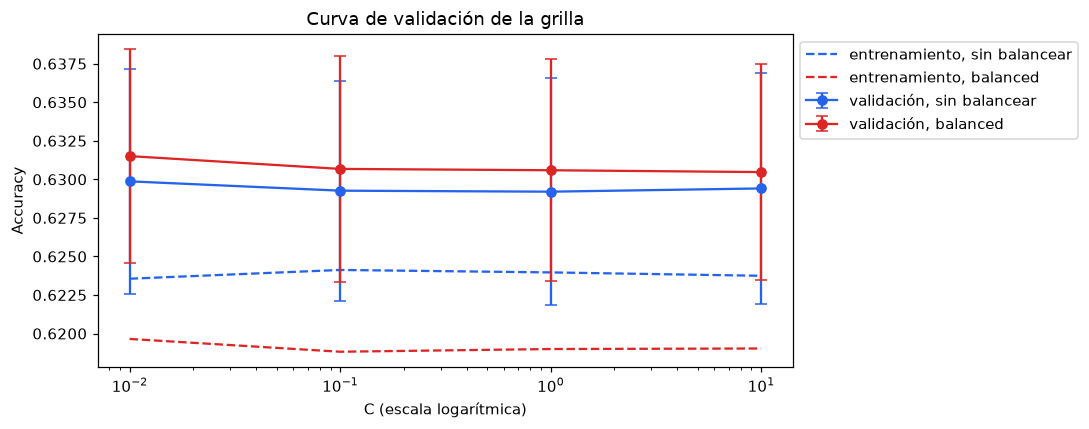

In [17]:
r = pd.DataFrame(busqueda.cv_results_)
fig, ax = plt.subplots(figsize=(10, 4))
for peso, color in [(None, '#2563eb'), ('balanced', '#dc2626')]:
    g = r[r.param_clasificador__class_weight.map(lambda x: x == peso)].sort_values('param_clasificador__C')
    nombre = 'sin balancear' if peso is None else 'balanced'
    ax.errorbar(g.param_clasificador__C.astype(float), g.mean_test_accuracy, yerr=g.std_test_accuracy,
                marker='o', capsize=4, color=color, label=f'validación, {nombre}')
    ax.plot(g.param_clasificador__C.astype(float), g.mean_train_accuracy, linestyle='--', color=color,
            label=f'entrenamiento, {nombre}')
ax.set(xscale='log', xlabel='C (escala logarítmica)', ylabel='Accuracy',
       title='Curva de validación de la grilla')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

**Conclusión:**

- **`C` casi no cambia nada.** Todas las combinaciones dan entre 62,92 % y 63,15 %, con desvíos de 0,7. La logística no estaba sobreajustando (62 % en entrenamiento, 63 % en validación), así que regularizar más o menos no mueve el resultado. Se ve en la curva: las líneas están casi planas.
- **Lo que sí cambia es `class_weight`, aunque no en la accuracy.** Con `C = 0,01`, pasar de `None` a `balanced` sube la accuracy de 62,99 % a 63,15 %: +0,16 puntos, menos que el desvío. Lo que cambia es cómo reparte los errores:

| `class_weight` | Accuracy | Recall gana A | Recall gana B |
|---|---|---|---|
| `None` | 62,99 % | 73,3 % | 51,3 % |
| `balanced` | 63,15 % | 65,6 % | 60,4 % |

- **Nuestra decisión sobre las clases: `class_weight='balanced'`.** En la métrica que declaramos no cuesta nada, y el modelo deja de inclinarse por A solo porque A gana un poco más seguido. El umbral queda en 0,50: no lo movimos además, porque es otra palanca para el mismo intercambio.
- **Ganador de la grilla:** `C = 0,01` con `balanced`, con 63,15 % ± 0,69 en validación.

### 9.1 ¿La decisión cambia con las 18 columnas?

La comparación de la sección 7 se hizo con 27 columnas. Para no quedarnos con la duda, volvemos a medir la mejor combinación de cada familia, ahora con las 18 columnas finales y los mismos folds.

In [18]:
filas18 = {}
for nombre, b in busquedas.items():
    clf = clone(b.best_estimator_.named_steps['clasificador'])
    if nombre == FAMILIA:
        clf = clone(modelo_final.named_steps['clasificador'])
    filas18[nombre], _ = medir(armar(clf, COLUMNAS_FINAL), X_train, y_train, cv)
tabla_modelos_18 = pd.DataFrame(filas18).T
display(tabla_modelos_18.round(4))
mejor18, limite18, elegido18 = cm.elegir_simple(tabla_modelos_18, ORDEN_SIMPLICIDAD)
print(f'Mejor promedio: {mejor18}. Límite: {limite18:.4f}. Elegido: {elegido18}.')

,accuracy,desvío,accuracy train,f1 macro,recall A,recall B
regresión logística,0.6315,0.0069,0.6197,0.6297,0.6559,0.6035
árbol de decisión,0.6237,0.0097,0.6128,0.6170,0.7053,0.5305
random forest,0.6319,0.0077,0.6561,0.6237,0.7295,0.5207
gradient boosting,0.6297,0.0080,0.6317,0.6231,0.7141,0.5336


Mejor promedio: random forest. Límite: 0.6243. Elegido: regresión logística.


**Conclusión:** con las 18 columnas la decisión no cambia. El random forest sigue con el mejor promedio (63,19 % ± 0,77), pero la logística ajustada (63,15 % ± 0,69) queda a 0,04 puntos: prácticamente empatados. El boosting da 62,97 % y el árbol 62,37 %. **Nos quedamos con la logística.**

## 10. Lo que congelamos antes de mirar el test

Desde acá no cambiamos nada más. Esta es la configuración final, elegida solo con validación cruzada sobre el entrenamiento:

In [19]:
fila_ganadora = tabla_grilla.iloc[0]
congelado = pd.DataFrame([
    ('Métrica principal', 'accuracy'),
    ('Piso', 'DummyClassifier (predice siempre «gana A»)'),
    ('Modelo', FAMILIA),
    ('Variante de columnas', VARIANTE),
    ('Cantidad de columnas', len(COLUMNAS_FINAL)),
    ('log1p en matches_prior', 'sí' if USAR_LOG else 'no'),
    ('C', busqueda.best_params_['clasificador__C']),
    ('class_weight', str(busqueda.best_params_['clasificador__class_weight'])),
    ('Umbral', UMBRAL),
    ('Accuracy en validación', f"{fila_ganadora.mean_test_accuracy:.4f} ± {fila_ganadora.std_test_accuracy:.4f}"),
    ('Validación', f'{N_SPLITS} folds temporales (TimeSeriesSplit por días)'),
    ('Corte del test', f'{CORTE_TEST:%d/%m/%Y}'),
    ('Semilla', SEMILLA),
], columns=['Decisión', 'Valor']).set_index('Decisión')
display(congelado)
display(pd.DataFrame({'columna del modelo final': COLUMNAS_FINAL}, index=range(1, len(COLUMNAS_FINAL) + 1)))

,Valor
Decisión,
Métrica principal,accuracy
Piso,DummyClassifier (predice siempre «gana A»)
Modelo,regresión logística
Variante de columnas,sin contadores
Cantidad de columnas,18
log1p en matches_prior,sí
C,0.01
class_weight,balanced
Umbral,0.5


,columna del modelo final
1,bo_type
2,tier
3,elo_advantage_a
4,ranking_score_advantage_a
5,round_winrate_last20_advantage_a
6,form_last5_advantage_a
7,same_bo_winrate_last20_advantage_a
8,same_tier_winrate_last20_advantage_a
9,lineup_stability_last5_advantage_a
10,h2h_team_a_winrate_last5


## 11. El modelo final, leído

A partir de acá **el modelo ya no cambia**. Lo que sigue no son pruebas para elegir: es leer el modelo terminado, que es lo que pide la consigna, en tres partes:

1. **Cuánto acierta:** lo medimos una sola vez sobre el test (esta sección).
2. **Dónde y por qué se equivoca:** matrices de confusión (11.1) y la lectura de los errores, ampliada en esta versión (11.2).
3. **En qué se apoya:** importancia por permutación y coeficientes (sección 12).

Usamos las predicciones del test para entender al modelo, nunca para cambiarlo.

In [20]:
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= UMBRAL).astype(int)
piso = armar(DummyClassifier(strategy='most_frequent'), COLUMNAS_FINAL).fit(X_train, y_train)
tabla_test = pd.DataFrame({'piso': metricas(y_test, piso.predict(X_test)),
                           'modelo final': metricas(y_test, pred_test)}).T
display(tabla_test.round(4))
reporte = pd.DataFrame(classification_report(y_test, pred_test, target_names=['gana B', 'gana A'],
                                             output_dict=True)).T
display(reporte.round(4))

,accuracy,f1 macro
piso,0.5451,0.3528
modelo final,0.6514,0.6485


,precision,recall,f1-score,support
gana B,0.6171,0.6159,0.6165,4012.0000
gana A,0.6800,0.6811,0.6805,4807.0000
accuracy,0.6514,0.6514,0.6514,0.6514
macro avg,0.6485,0.6485,0.6485,8819.0000
weighted avg,0.6514,0.6514,0.6514,8819.0000


**Conclusión:**

- En el test (8.819 series desde el 01/03/2026) el modelo acierta el **65,1 %**. El piso, que dice siempre «gana A», acierta el 54,5 %: le ganamos por **10,6 puntos**.
- El resultado se parece al de validación (63,2 %), incluso un poco mejor. Nada indica que el número de validación estuviera inflado.
- **¿Es mucho o poco?** Para mostrar un favorito antes de la serie, es una mejora clara sobre adivinar. Pero el modelo se sigue equivocando en una de cada tres series: en CS2 pesan cosas que no están en los datos, como el veto de mapas, el rendimiento del día o los cambios de jugadores.
- **El modelo no se olvida de ninguna clase.** El F1 macro da 0,649, casi igual a la accuracy, y el recall está parejo: 68,1 % para A y 61,6 % para B.

### 11.0 Los otros modelos en el test, como contexto

El modelo ya está congelado. Solo para tener contexto —no para elegir— entrenamos la mejor combinación de cada familia con las 18 columnas y todo el entrenamiento, y la medimos en el mismo test.

In [21]:
modelos_test, proba_otros = {}, {}
for nombre, b in busquedas.items():
    if nombre == FAMILIA:
        m = modelo_final
    else:
        m = armar(clone(b.best_estimator_.named_steps['clasificador']), COLUMNAS_FINAL).fit(X_train, y_train)
    proba_otros[nombre] = m.predict_proba(X_test)[:, 1]
    modelos_test[nombre] = {**metricas(y_test, (proba_otros[nombre] >= UMBRAL).astype(int)),
                            'brier': brier_score_loss(y_test, proba_otros[nombre])}
tabla_test_modelos = pd.DataFrame(modelos_test).T
display(tabla_test_modelos.round(4))

,accuracy,f1 macro,brier
regresión logística,0.6514,0.6485,0.2176
árbol de decisión,0.6383,0.6282,0.2223
random forest,0.6513,0.6409,0.2175
gradient boosting,0.6532,0.6442,0.2178


**Conclusión:** en el test los cuatro modelos dan prácticamente lo mismo: logística 65,14 %, random forest 65,13 %, gradient boosting 65,32 % y árbol 63,83 %. El boosting acierta 16 series más que la logística sobre 8.819 (0,18 puntos): menos que cualquier desvío que medimos en validación, y no lo usamos para elegir, porque el test se mira una sola vez. El Brier, que mide qué tan buenas son las probabilidades y no solo el acierto, también empata (0,2175–0,2178), salvo el árbol (0,2223), que con 3 niveles solo puede dar 8 probabilidades distintas.

Lo importante para la elección: **el test confirma lo que dijo la validación**. Ningún modelo complejo se escapa.

### 11.1 Dónde se equivoca: matrices de confusión

- **Por fila:** de las series que ganó cada equipo, qué parte acertamos. La diagonal es el recall.
- **Por columna:** de las veces que dijimos «gana A» (o «gana B»), qué parte era correcta. La diagonal es la precision.

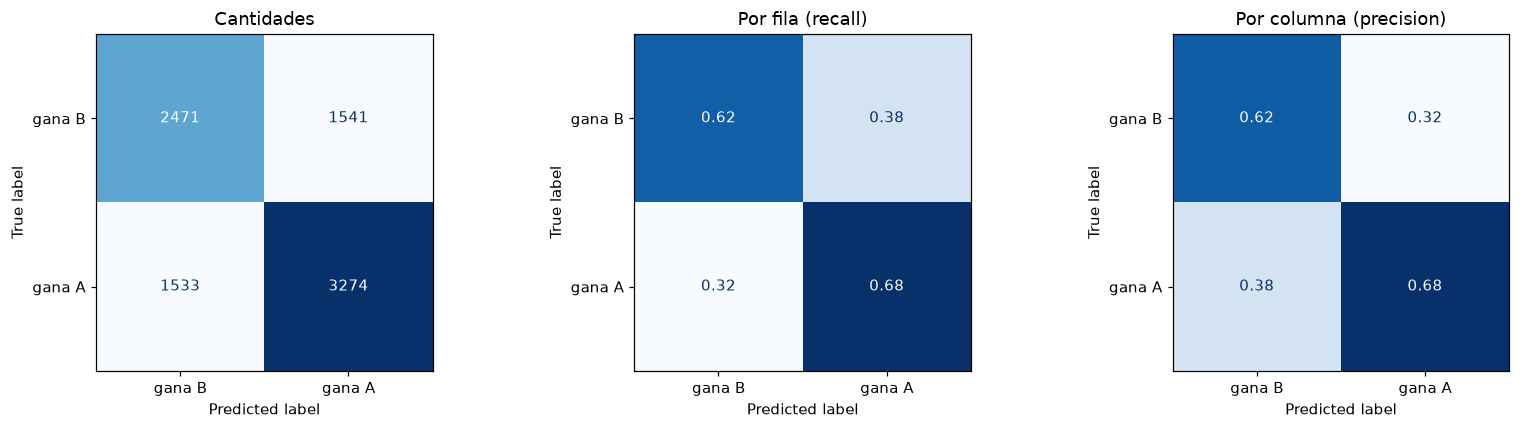

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, norma, titulo in zip(axes, [None, 'true', 'pred'], ['Cantidades', 'Por fila (recall)', 'Por columna (precision)']):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['gana B', 'gana A'], normalize=norma,
                                            values_format='d' if norma is None else '.2f', cmap='Blues',
                                            colorbar=False, ax=ax)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

**Conclusión:** de 3.074 errores, 1.541 son series que ganó B y dijimos A, y 1.533 son series que ganó A y dijimos B. Los errores están repartidos casi mitad y mitad.

- **Por fila:** recuperamos el 68 % de las victorias de A y el 62 % de las de B.
- **Por columna:** cuando decimos «gana A» acertamos el 68 % de las veces, y cuando decimos «gana B», el 62 %.

Al modelo le cuesta un poco más reconocer cuándo gana B, que es la clase que gana menos seguido.

### 11.2 Dónde y por qué se equivoca

Esta sección es la que ampliamos. Vamos de lo general a lo particular:

1. **¿Cuánto confiaba el modelo cuando se equivocó?** Errores por tramo de confianza.
2. **¿Qué tan parejo era el partido?** Errores por diferencia de Elo, y las «sorpresas».
3. **¿En qué tipo de partido?** Por formato, tier e historia previa.
4. **¿Cuándo?** Mes a mes en el test.
5. **¿Hay algo que avise?** El perfil de los errores con mucha confianza.
6. **¿Es culpa de la logística?** Si los otros modelos fallan en las mismas series.
7. **¿Las probabilidades dicen la verdad?** La calibración.
8. **Casos concretos.**

Todas las cuentas salen de `cm.detalle_predicciones`, una tabla con una fila por serie del test, la probabilidad del modelo y lo que sirve para leer cada error. La aplicación usa la misma tabla.

In [23]:
detalle = cm.detalle_predicciones(test, proba_test)
errores = detalle[~detalle.acierto]
print(f'{len(errores):,} errores en {len(detalle):,} series ({1 - detalle.acierto.mean():.1%}).')

3,074 errores en 8,819 series (34.9%).


#### 1. Por confianza: el modelo sabe cuándo duda

Para cada serie, la **confianza** es la probabilidad que el modelo le dio a su favorito (entre 50 % y 100 %). Agrupamos el test por tramos de confianza y medimos cuánto acierta en cada uno.

In [24]:
display(graf.tabla_confianza(detalle).drop(columns=['texto', 'texto_cuota', 'texto_n']).round(3))
print('Errores con confianza menor a 60 %:', f"{(errores.confianza < 0.6).mean():.1%}")
graf.g_confianza(detalle)

,tramo,series,accuracy,confianza,cuota
0,50–55 %,2015,0.540,0.525,1.850
1,55–60 %,1593,0.584,0.574,1.713
2,60–65 %,1442,0.633,0.625,1.579
3,65–70 %,1279,0.680,0.674,1.470
4,70–75 %,1047,0.730,0.724,1.370
5,75–80 %,704,0.777,0.774,1.287
6,80 % o más,739,0.855,0.845,1.169


Errores con confianza menor a 60 %: 51.7%


alt.LayerChart(...)

**Conclusión:** el modelo **sabe cuándo duda**.

- **La mitad de los errores (51,7 %) son de series donde el modelo dio menos de 60 %.** Ahí acierta 54–58 %: casi una moneda. No se está equivocando con firmeza: está diciendo «no sé» y eligiendo apenas.
- **Cuando da 80 % o más, acierta el 85,5 %** (739 series). Cuando da 70–80 %, entre 73 % y 78 %.
- **La rayita blanca (lo que dice el modelo) queda pegada a la barra (lo que pasa)** en todos los tramos. Por ejemplo, en 70–75 % dice 72,4 % en promedio y acierta 73,0 %. Lo volvemos a mirar en el punto 7.
- **La cuota mínima** (1 / accuracy del tramo) traduce esto a apuestas: apostarle siempre al favorito cuando el modelo duda solo conviene si la casa paga más de 1,85; cuando está seguro, alcanza con 1,17. Lo usamos en la aplicación.

#### 2. Por diferencia de Elo: la mayoría de los errores son sorpresas

Llamamos **sorpresa** a una serie que ganó el equipo que llegaba con **menos** Elo. Un modelo que se apoya sobre todo en el Elo (sección 12) va a errar casi todas las sorpresas por construcción. La pregunta es cuántos de sus errores son eso.

In [25]:
display(cm.tabla_por(detalle, 'tramo_elo', cm.ETIQUETAS_ELO).round(3))
sorpresas = detalle.groupby('sorpresa').agg(series=('acierto', 'size'), accuracy=('acierto', 'mean'))
sorpresas.index = sorpresas.index.map({False: 'ganó el de más Elo', True: 'sorpresa: ganó el de menos Elo'})
display(sorpresas.round(3))
print(f'Sorpresas en el test: {detalle.sorpresa.mean():.1%}. Errores que son sorpresas: {errores.sorpresa.mean():.1%}.')

t = detalle.assign(resultado=np.where(detalle.acierto, 'Acierto', 'Error'),
                   tipo=np.where(detalle.sorpresa, 'Sorpresa (ganó el de menos Elo)', 'Ganó el de más Elo'))
alt.Chart(t[['tramo_elo', 'resultado', 'tipo']].astype(str)).mark_bar().encode(
    x=alt.X('tramo_elo:O', sort=cm.ETIQUETAS_ELO, title='Diferencia de Elo entre los dos equipos (puntos)',
            axis=alt.Axis(labelAngle=0)),
    y=alt.Y('count():Q', title='Series del test'),
    color=alt.Color('resultado:N', scale=graf.ESC_RESULTADO, title=None),
    column=alt.Column('tipo:N', title=None, sort=['Ganó el de más Elo', 'Sorpresa (ganó el de menos Elo)'])
).properties(width=330, height=240, title='Casi todos los errores están del lado de las sorpresas')

,series,accuracy,prob_media
tramo_elo,,,
0–50,2916,0.574,0.565
50–100,2323,0.615,0.610
100–150,1543,0.667,0.669
150–200,983,0.756,0.728
200–300,803,0.816,0.788
300–400,209,0.856,0.856
400 o más,42,0.905,0.919


,series,accuracy
sorpresa,,
ganó el de más Elo,5641,0.899
sorpresa: ganó el de menos Elo,3178,0.212


Sorpresas en el test: 36.0%. Errores que son sorpresas: 81.5%.


alt.Chart(...)

**Conclusión:** el error principal del modelo tiene nombre: **las sorpresas**.

- **El 36,0 % de las series del test las ganó el equipo con menos Elo.** En CS2 pasa seguido: un BO3 se define en pocos mapas y cada mapa en pocas rondas.
- En esas series el modelo acierta solo el **21,2 %**; en las otras, el **89,9 %**.
- **El 81,5 % de los errores son sorpresas.** El resto son series donde el favorito por Elo ganó pero el modelo lo había descartado por otras columnas (ranking, rondas, experiencia).
- **Con poca diferencia de Elo el modelo casi tira una moneda:** con menos de 50 puntos acierta 57,4 % (2.916 series, el tramo más grande). Con más de 200 puntos, más del 81 %.

Por eso el modelo «falla»: no le erra a la lógica del partido, le erra a los partidos que contradicen esa lógica. Para acertarlos haría falta información que no está en el Silver (sección 5).

#### 3. Por tipo de partido

Partimos el test por formato (`bo_type`), nivel del torneo (`tier`) e historia previa. «Historia corta» quiere decir que al menos uno de los dos equipos tenía menos de 5 partidos anteriores.

In [26]:
filas = []
for variable in ['bo_type', 'tier', 'historia']:
    for valor, gr in detalle.groupby(variable):
        filas.append({'corte': variable, 'grupo': str(valor), 'series': len(gr), '% gana A': 100 * gr.real.mean(),
                      '% sorpresas': 100 * gr.sorpresa.mean(), 'accuracy': gr.acierto.mean(),
                      'f1 macro': f1_score(gr.real, gr.predicho, average='macro')})
tabla_tipos = pd.DataFrame(filas)
display(tabla_tipos.round(3))

# El Elo separa menos en tier a: cuánto gana el favorito por Elo en cada tier, en todo el dataset (Entrega 2, H2).
fav = df[df.elo_advantage_a != 0]
gana_fav = np.where(fav.elo_advantage_a > 0, fav.target_team_a_won, 1 - fav.target_team_a_won)
display(pd.Series(gana_fav, index=fav.index).groupby(fav.tier).agg(['mean', 'size'])
        .rename(columns={'mean': 'gana el de más Elo', 'size': 'series'}).round(3))

alt.Chart(tabla_tipos).mark_point(filled=True, size=110, color=graf.ACENTO, opacity=1).encode(
    x=alt.X('accuracy:Q', scale=alt.Scale(domain=[0.5, 0.72]), axis=alt.Axis(format='.0%'), title='Accuracy en el test'),
    y=alt.Y('grupo:N', title=None, sort=None),
    row=alt.Row('corte:N', title=None, sort=['tier', 'bo_type', 'historia']),
    tooltip=['corte', 'grupo', 'series', alt.Tooltip('accuracy:Q', format='.1%'), alt.Tooltip('% sorpresas:Q', format='.1f')]
).properties(width=420, height=alt.Step(22), title='Accuracy por tipo de partido (puntos y no barras: el eje empieza en 50 %)'
).resolve_scale(y='independent')

,corte,grupo,series,% gana A,% sorpresas,accuracy,f1 macro
0,bo_type,1,1412,57.861,35.977,0.679,0.672
1,bo_type,3,7345,53.873,36.065,0.646,0.644
2,bo_type,5,62,53.226,33.871,0.629,0.606
3,tier,a,273,52.381,41.026,0.586,0.586
4,tier,b,3165,53.839,34.818,0.651,0.649
5,tier,c,4881,55.296,36.857,0.655,0.650
6,tier,s,500,52.200,33.000,0.660,0.659
7,historia,historia corta,1436,64.345,37.744,0.672,0.621
8,historia,los dos con 5 o más,7383,52.594,35.704,0.647,0.647


,gana el de más Elo,series
tier,,
a,0.575,1352
b,0.636,14538
c,0.613,25009
d,0.590,105
s,0.623,2350


alt.Chart(...)

**Conclusión:**

- **Donde más se equivoca es en tier a:** 58,6 % de aciertos, contra 65–66 % en los tiers b, c y s. Hay dos razones que se suman. En tier a el Elo es el que menos separa: el de más Elo gana el 57,5 % de las series, contra 61–64 % en los otros tiers (H2 de la Entrega 2). Y es el tier con más sorpresas del test: 41,0 %, contra 33–37 % en el resto. Son 273 series, así que la diferencia hay que tomarla con cuidado.
- **Por formato:** acierta más en BO1 (67,9 %) que en BO3 (64,6 %), con la misma proporción de sorpresas (36 %). El BO5 da 62,9 %, pero son 62 series: no alcanza para concluir nada.
- **Historia corta:** cuando uno de los equipos tiene menos de 5 partidos previos, A gana el 64 % de las veces (el equipo nuevo suele ser B, por su ID más alto, y suele perder). La accuracy es alta (67,2 %), pero el F1 macro baja a 0,62 porque en esos partidos casi siempre decimos «gana A».

#### 4. A lo largo del test: el mes del parón

El test cubre siete meses y medio. Si el mundo cambiara rápido (parches, rosters), el modelo debería empeorar con el tiempo.

In [27]:
mensual = detalle.groupby('mes').agg(series=('acierto', 'size'), accuracy=('acierto', 'mean'),
                                     confianza=('confianza', 'mean'), sorpresas=('sorpresa', 'mean'),
                                     fav_inactivo=('fav_inactivo_30d', 'mean')).reset_index()
display(mensual.round(3))
base = alt.Chart(mensual).encode(x=alt.X('yearmonth(mes):T', title=None, axis=alt.Axis(format='%b %Y')))
(base.mark_line(point=True, color=graf.ACENTO, strokeWidth=3).encode(
    y=alt.Y('accuracy:Q', scale=alt.Scale(domain=[0.55, 0.72]), axis=alt.Axis(format='.0%'), title='Accuracy'),
    tooltip=[alt.Tooltip('yearmonth(mes):T', title='Mes'), 'series', alt.Tooltip('accuracy:Q', format='.1%'),
             alt.Tooltip('sorpresas:Q', format='.1%')])
 + base.mark_line(strokeDash=[4, 3], color=graf.SUAVE).encode(y='confianza:Q')
).properties(width=560, height=220, title='Accuracy por mes (línea llena) y confianza media del modelo (punteada)')

,mes,series,accuracy,confianza,sorpresas,fav_inactivo
0,2026-03-01,1693,0.653,0.652,0.356,0.012
1,2026-04-01,1420,0.668,0.646,0.345,0.019
2,2026-05-01,1370,0.664,0.635,0.358,0.022
3,2026-06-01,697,0.648,0.629,0.357,0.046
4,2026-07-01,768,0.600,0.642,0.398,0.091
5,2026-08-01,1105,0.660,0.631,0.357,0.045
6,2026-09-01,1136,0.630,0.640,0.379,0.035
7,2026-10-01,630,0.670,0.659,0.341,0.033


alt.LayerChart(...)

**Conclusión:** el modelo **no se degrada con el tiempo**: acierta 65 % en marzo y 67 % en octubre, siete meses después de entrenado. La excepción es **julio (60,0 %)**, el peor mes por 3 puntos. Es el mes que sigue al parón de mitad de año: el 9,1 % de las series tenía un favorito que no había jugado en los 30 días anteriores (en marzo, el 1,2 %) y hubo más sorpresas (39,8 %, contra 34–38 % en los otros meses). Con estadísticas de hace más de un mes, el modelo mira una foto vieja. La confianza media del modelo, en cambio, no bajó en julio: **no se dio cuenta** de que sabía menos. Es una limitación concreta: el modelo no sabe cuándo sus datos están desactualizados.

#### 5. Los errores con mucha confianza: ¿había algo que avisara?

Tomamos las series donde el modelo le dio **70 % o más** a su favorito y comparamos las que acertó con las que falló. Si los errores tuvieran un perfil distinto —favorito inactivo, alineación cambiada, sin ranking, tier a, BO1—, sería información que el modelo no está usando.

In [28]:
seguras = detalle[detalle.confianza >= 0.7].copy()
seguras['tier a'] = seguras.tier.eq('a')
seguras['BO1'] = seguras.bo_type.eq(1)
seguras['sin H2H'] = seguras.h2h_last5_count.eq(0)
perfil = seguras.groupby(seguras.acierto.map({True: 'aciertos', False: 'errores'})).agg(
    series=('acierto', 'size'),
    dif_elo_media=('dif_elo_abs', 'mean'),
    favorito_sin_jugar_30d=('fav_inactivo_30d', 'mean'),
    favorito_cambio_alineacion=('fav_cambio_alineacion', 'mean'),
    sin_ranking=('sin_ranking', 'mean'),
    tier_a=('tier a', 'mean'), bo1=('BO1', 'mean'), sin_h2h=('sin H2H', 'mean')).T
display(perfil.round(3))

acierto,aciertos,errores
series,1943.000,547.000
dif_elo_media,199.109,174.115
favorito_sin_jugar_30d,0.024,0.018
favorito_cambio_alineacion,0.251,0.236
sin_ranking,0.312,0.243
tier_a,0.031,0.053
bo1,0.183,0.183
sin_h2h,0.585,0.556


**Conclusión:** **no hay una señal clara que avise.** Entre las 2.490 series con 70 % o más, los 547 errores y los 1.943 aciertos se parecen:

- El favorito sin jugar en 30 días aparece en el 1,8 % de los errores y en el 2,4 % de los aciertos. Que el favorito haya cambiado jugadores, en el 23,6 % y el 25,1 %. Los BO1, en el 18,3 % de los dos.
- Las diferencias que sí hay son chicas y van en la dirección esperable: en los errores la ventaja de Elo era algo menor (174 puntos contra 199), hay un poco más de tier a (5,3 % contra 3,1 %) y un poco menos de series sin ranking.

Es decir, **las sorpresas con mucha confianza no tienen un perfil distinto en nuestras columnas**. Lo que las decide —el veto de mapas, un suplente de último momento, un jugador en mal día, la preparación específica contra ese rival— no está en el Silver. Ningún modelo entrenado con estas columnas las va a poder anticipar (lo confirma el punto siguiente).

#### 6. ¿Los otros modelos fallan en las mismas series?

Si el random forest o el boosting acertaran justo donde la logística falla, valdría la pena combinarlos. Si fallan en las mismas, el error no es del modelo: es de la información que hay en los datos.

In [29]:
pred_otros = pd.DataFrame({n: (p >= UMBRAL).astype(int) for n, p in proba_otros.items()})
acierto_otros = pred_otros.eq(y_test.to_numpy(), axis=0)
falla_log = ~acierto_otros[FAMILIA]
acuerdo = pd.DataFrame({
    'dice lo mismo que la logística': pred_otros.eq(pred_otros[FAMILIA], axis=0).mean(),
    'también falla donde falla la logística': acierto_otros[falla_log].eq(False).mean(),
}).drop(index=FAMILIA)
display(acuerdo.round(3))
cuantos = (~acierto_otros).sum(axis=1)
display(cuantos.value_counts().sort_index().rename_axis('modelos que fallan (de 4)').to_frame('series'))
print(f'Series que fallan los cuatro modelos: {(cuantos == 4).mean():.1%} del test; '
      f'son el {(cuantos[falla_log] == 4).mean():.1%} de los errores de la logística.')

,dice lo mismo que la logística,también falla donde falla la logística
árbol de decisión,0.844,0.796
random forest,0.909,0.870
gradient boosting,0.910,0.869


,series
modelos que fallan (de 4),
0,4855
1,717
2,355
3,598
4,2294


Series que fallan los cuatro modelos: 26.0% del test; son el 74.6% de los errores de la logística.


**Conclusión:** **los errores no son de la logística, son de los datos.**

- El random forest y el boosting dicen lo mismo que la logística en el 91 % de las series, y el árbol en el 84 %.
- Donde la logística falla, el random forest y el boosting también fallan el 87 % de las veces.
- **2.294 series (26,0 % del test) las fallan los cuatro modelos**, y son el **74,6 % de los errores de la logística**. Solo 717 series las falla un único modelo.

Combinar modelos no ayudaría: se equivocan juntos. Es la misma conclusión de la sección 7, vista desde los errores: con estas columnas, el techo está cerca del 65 %, y para subirlo hacen falta datos nuevos (mapas, vetos, rendimiento individual reciente), no un modelo más complejo.

#### 7. ¿Las probabilidades dicen la verdad? Calibración

En la Entrega 3 dejamos esto pendiente: no habíamos comprobado si, cuando el modelo dice 70 %, el equipo gana 7 de cada 10 veces. Importa para la aplicación, porque ahí mostramos la probabilidad y la usamos para comparar contra las cuotas de una apuesta. Agrupamos el test por la probabilidad de «gana A» en tramos de 10 puntos y comparamos con la proporción real.

In [30]:
tramo = pd.cut(detalle.prob_a, np.linspace(0, 1, 11))
calib = detalle.groupby(tramo, observed=True).agg(series=('real', 'size'), predicho=('prob_a', 'mean'),
                                                    real=('real', 'mean')).reset_index(drop=True)
display(calib.round(3))
print(f'Brier: {brier_score_loss(y_test, proba_test):.4f} · log loss: {log_loss(y_test, proba_test):.4f} · '
      f'probabilidad media de A: {proba_test.mean():.3f} · proporción real de A: {y_test.mean():.3f}')
diag = alt.Chart(pd.DataFrame({'x': [0, 1]})).mark_line(color=graf.SUAVE, strokeDash=[4, 3]).encode(x='x:Q', y='x:Q')
puntos = alt.Chart(calib).mark_line(point=True, color=graf.ACENTO, strokeWidth=3).encode(
    x=alt.X('predicho:Q', title='Probabilidad de «gana A» según el modelo', axis=alt.Axis(format='.0%')),
    y=alt.Y('real:Q', title='Proporción real de series que ganó A', axis=alt.Axis(format='.0%')),
    tooltip=['series', alt.Tooltip('predicho:Q', format='.1%'), alt.Tooltip('real:Q', format='.1%')])
(diag + puntos).properties(width=360, height=360, title='Calibración en el test: cerca de la diagonal es «dice la verdad»')

,series,predicho,real
0,22,0.076,0.091
1,273,0.162,0.176
2,766,0.256,0.304
3,1171,0.352,0.364
4,1772,0.454,0.465
5,1836,0.547,0.583
6,1550,0.648,0.670
7,985,0.744,0.790
8,396,0.836,0.869
9,48,0.924,0.896


Brier: 0.2176 · log loss: 0.6245 · probabilidad media de A: 0.519 · proporción real de A: 0.545


alt.LayerChart(...)

**Conclusión:** las probabilidades **están bastante bien calibradas**, con un corrimiento conocido.

- Los puntos siguen la diagonal: cuando el modelo le da a A entre 60 % y 70 % (65 % en promedio), A gana el 67 %; cuando le da entre 80 % y 90 %, el 87 %.
- **Quedan entre 1 y 5 puntos por encima de la diagonal:** A gana un poco más seguido de lo que el modelo dice. En promedio el modelo le da a A 51,9 % y A gana el 54,5 %. Es el efecto de `class_weight='balanced'` (sección 9), que empuja a propósito hacia B para emparejar el recall. Es una corrección chica y la dejamos, porque balancear no costó accuracy.
- **Brier 0,218 y log loss 0,624**, contra 0,248 y 0,690 de decir siempre 54,5 %.

Con esto corregimos lo que la Entrega 3 dejó como advertencia («no comprobamos si están calibradas»). Las probabilidades se pueden leer como chances, con la salvedad del corrimiento hacia B. En la aplicación las comparamos con las cuotas de una apuesta, y lo aclaramos ahí.

#### 8. Casos concretos

Las cinco series donde el modelo se equivocó con más confianza, y una mirada a la más notoria.

In [31]:
columnas_caso = ['start_at_utc', 'team_a_name', 'team_b_name', 'tournament_name', 'bo_type', 'tier',
                 'elo_advantage_a', 'team_a_matches_last30d', 'team_b_matches_last30d', 'prob_a', 'favorito', 'ganador',
                 'post_team_a_maps_won', 'post_team_b_maps_won']
display(errores.sort_values('confianza', ascending=False)[columnas_caso].head(5).round(3))

,start_at_utc,team_a_name,team_b_name,tournament_name,bo_type,tier,elo_advantage_a,team_a_matches_last30d,team_b_matches_last30d,prob_a,favorito,ganador,post_team_a_maps_won,post_team_b_maps_won
5697,2026-07-24 15:50:00+00:00,Vitality,Liquid,BLAST Bounty Summer 2026: Closed Qualifier,3,a,461.061,0,0,0.938,Vitality,Liquid,0,2
2695,2026-04-23 17:00:00+00:00,Lilmix,BET-M,ESL Challenger League Season 51: Europe - Cup 4,3,b,-464.306,10,7,0.072,BET-M,Lilmix,2,1
5706,2026-07-24 18:00:00+00:00,FURIA,DENDELE,BLAST Bounty Summer 2026: Closed Qualifier,3,a,545.123,0,0,0.927,FURIA,DENDELE,1,2
3514,2026-05-11 11:58:08+00:00,THUNDER dOWNUNDER,Haunted House,Asian Champions League 2026,3,a,320.131,4,1,0.920,THUNDER dOWNUNDER,Haunted House,0,2
7360,2026-09-09 03:10:00+00:00,The MongolZ,5star,FISSURE Playground 3,3,s,389.446,3,4,0.914,The MongolZ,5star,0,2


**Conclusión:** de los cinco errores con más confianza, **dos son del mismo día y del mismo torneo**: Vitality vs. Liquid y FURIA vs. DENDELE, el 24/07/2026, en la clasificatoria cerrada de la BLAST Bounty Summer 2026 (tier a).

**Vitality vs. Liquid.** El modelo le dio 93,8 % a Vitality, que llegaba con 461 puntos más de Elo, mejor ranking, 5 victorias en los 5 cruces previos y mejor winrate de rondas. Ganó Liquid 2-0. **Ninguno de los dos había jugado en los 30 días anteriores**, y lo mismo pasaba con FURIA y DENDELE (92,7 % para FURIA, ganó DENDELE 2-1). Venían del parón de mitad de año. Todas sus estadísticas describían cómo jugaban más de un mes antes, y en ese tiempo un equipo puede cambiar jugadores, estrategia o mapas. Es el caso del punto 4, visto de cerca.

Los otros tres son sorpresas sin una explicación visible en los datos: equipos con 300 a 460 puntos menos de Elo que ganaron igual, en series con actividad normal. Es el punto 5: lo que decidió esas series no está en las columnas.

## 12. En qué se apoya el modelo

**Importancia por permutación** (Práctica 1): desordenamos una columna en el test y medimos cuánto baja la accuracy. Si baja mucho, el modelo depende de esa columna; si no cambia, no la usa. Repetimos 5 veces cada columna.

,columna,baja de accuracy,desvío
2,elo_advantage_a,0.0538,0.0059
3,ranking_score_advantage_a,0.0146,0.0021
11,team_b_matches_prior,0.0099,0.0016
4,round_winrate_last20_advantage_a,0.0076,0.0018
10,team_a_matches_prior,0.0052,0.0009
9,h2h_team_a_winrate_last5,0.0032,0.0011
5,form_last5_advantage_a,0.0024,0.0009
12,team_a_form_trend_5v5,0.0020,0.0012
13,team_b_form_trend_5v5,0.0014,0.0011
8,lineup_stability_last5_advantage_a,0.0012,0.0002


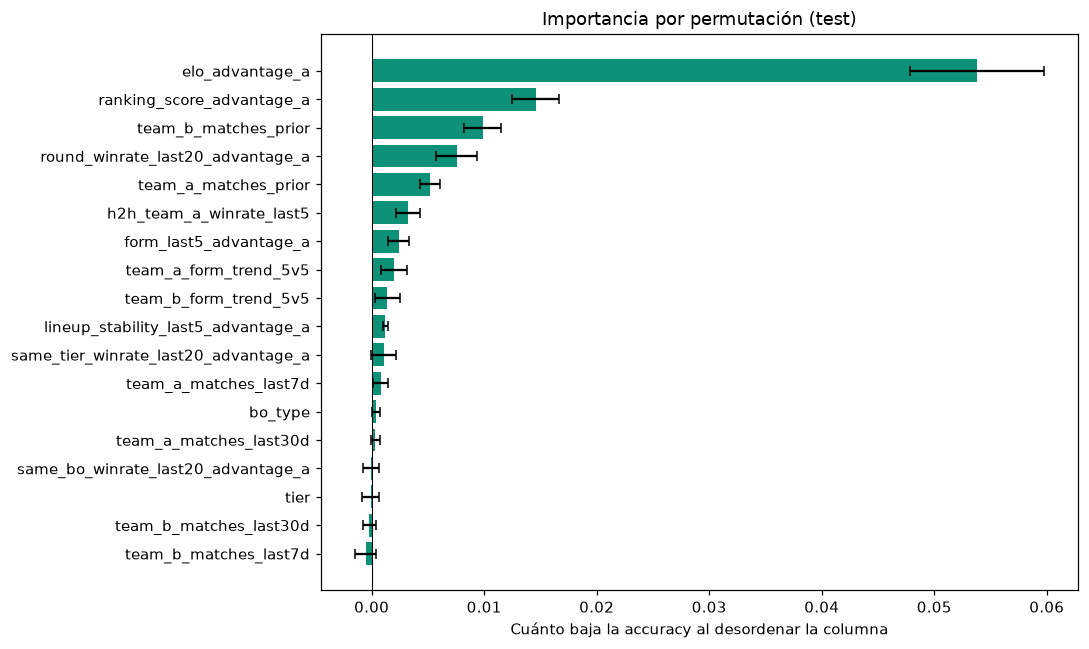

In [32]:
X_test_final = X_test[COLUMNAS_FINAL]
pi = permutation_importance(modelo_final, X_test_final, y_test, scoring='accuracy',
                            n_repeats=5, random_state=SEMILLA, n_jobs=N_JOBS)
importancias = pd.DataFrame({'columna': COLUMNAS_FINAL, 'baja de accuracy': pi.importances_mean,
                             'desvío': pi.importances_std}).sort_values('baja de accuracy', ascending=False)
display(importancias.round(4))
g = importancias.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(g.columna, g['baja de accuracy'], xerr=g['desvío'], color='#0d9278', capsize=3)
ax.axvline(0, color='black', lw=0.7)
ax.set(xlabel='Cuánto baja la accuracy al desordenar la columna', title='Importancia por permutación (test)')
plt.tight_layout(); plt.show()

**Conclusión:** el modelo es, básicamente, **«quién tiene más Elo»**.

- Desordenar la diferencia de Elo baja la accuracy **5,4 puntos**: más del triple que cualquier otra columna.
- Después vienen el ranking (1,5 puntos), la experiencia de B (1,0), el winrate de rondas (0,8) y la experiencia de A (0,5).
- El resto aporta muy poco: menos de 0,4 puntos cada una. Seis columnas dan prácticamente cero (entre −0,05 y +0,04 puntos): `same_bo_winrate_last20_advantage_a`, `tier`, `bo_type` y los partidos de los últimos 7 y 30 días. El modelo casi no las usa.

No sacamos esas columnas ahora: sería volver a elegir mirando el test. Si quisiéramos simplificar el modelo, habría que decidirlo con validación cruzada sobre el entrenamiento, no con el test.

### 12.1 Coeficientes de la logística

Un coeficiente positivo empuja hacia «gana A» y uno negativo hacia «gana B», con las demás columnas fijas. Como las numéricas están escaladas, el tamaño de los coeficientes se puede comparar entre ellas.

,variable,coeficiente
0,numericas__elo_advantage_a,0.3855
1,numericas__ranking_score_advantage_a,0.1970
2,historia__team_b_matches_prior,-0.1422
3,numericas__round_winrate_last20_advantage_a,0.1301
4,historia__team_a_matches_prior,0.0931
5,numericas__missingindicator_team_a_form_trend_5v5,-0.0843
6,categoricas__bo_type_5,0.0776
7,numericas__missingindicator_team_b_form_trend_5v5,0.0742
8,numericas__h2h_team_a_winrate_last5,0.0698
9,categoricas__bo_type_3,-0.0517


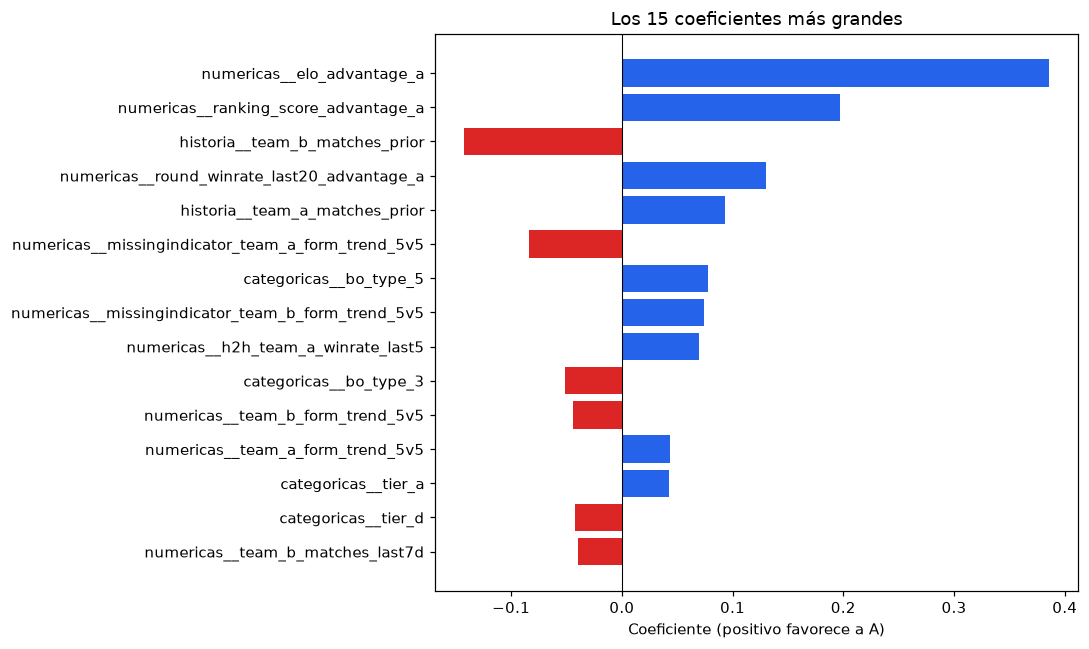

In [33]:
coeficientes = pd.DataFrame({'variable': modelo_final['preparar'].get_feature_names_out(),
                             'coeficiente': modelo_final['clasificador'].coef_[0]})
coeficientes = coeficientes.reindex(coeficientes.coeficiente.abs().sort_values(ascending=False).index)
display(coeficientes.round(4).reset_index(drop=True))
g = coeficientes.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(g.variable, g.coeficiente, color=np.where(g.coeficiente >= 0, '#2563eb', '#dc2626'))
ax.axvline(0, color='black', lw=0.7)
ax.set(xlabel='Coeficiente (positivo favorece a A)', title='Los 15 coeficientes más grandes')
plt.tight_layout(); plt.show()

**Conclusión:**

- **Los signos tienen sentido.** Más Elo que el rival (+0,39), mejor ranking (+0,20) y mejor winrate de rondas (+0,13) empujan a favor de A. La experiencia también: más partidos previos de A empujan hacia A (+0,09), y más partidos previos de B empujan hacia B (−0,14).
- **Un signo raro: `form_last5_advantage_a` da −0,04.** No significa que «estar en racha hace perder». La forma de los últimos 5 partidos está muy relacionada con el Elo y el winrate de rondas, y el coeficiente mide su efecto *dejando esas columnas fijas*. Lo útil de la racha ya lo captan las otras. Mirada sola, su importancia por permutación es positiva, aunque chica (0,24 puntos).
- **Los indicadores de faltante de la tendencia también tienen lógica:** −0,08 el de A y +0,07 el de B. Si a un equipo le falta la tendencia es porque tiene menos de 10 partidos, y los equipos con poca historia pierden más.
- **La columna que más pesa es el Elo, y no es una fuga.** Lidera las dos lecturas y no nos sorprende, porque resume los resultados anteriores de cada equipo. Para descartar una fuga, en la sección 3 lo recalculamos desde cero usando solo series que terminaron antes del inicio de cada partido, y coincide con el Silver en las 43.719 filas. El Elo de un partido no incluye su propio resultado.

## 13. Conclusión

**Qué predecimos y cómo lo medimos.** El ganador de una serie de CS2 antes de que empiece. Lo medimos con accuracy y validación cruzada temporal en 5 folds, más un test de 8.819 series posteriores al 01/03/2026.

**Resultado.**

| | Validación cruzada | Test |
|---|---|---|
| Piso (siempre «gana A») | 53,3 % | 54,5 % |
| Modelo final (logística) | 63,2 % ± 0,7 | 65,1 % |

**Por qué este modelo (corregido).** Comparamos cuatro familias, **cada una con su grilla de hiperparámetros**: logística 63,0 %, árbol de decisión 62,4 %, random forest 63,4 % y gradient boosting 63,2 %. El random forest da el mejor promedio, pero le gana a la logística por 0,3 puntos, menos que un desvío. Con más capacidad, los árboles memorizan y no generalizan mejor (7.3): la relación entre las columnas y el resultado es casi aditiva. En el test los cuatro empatan (63,8–65,3 %). Nos quedamos con la logística: rinde lo mismo, es la más simple de explicar y se puede llevar como fórmula a la aplicación.

**En qué se apoya.** Sobre todo en la diferencia de Elo. Después en el ranking, la experiencia de cada equipo y el winrate de rondas. El Elo no es una fuga: lo recalculamos desde cero con resultados anteriores y coincide.

**Dónde y por qué se equivoca (ampliado).**
- **En las sorpresas:** el 36 % de las series las ganó el de menos Elo, y son el 81,5 % de los errores.
- **Cuando duda:** la mitad de los errores son series donde dio menos de 60 %. Cuando da 80 % o más, acierta el 85,5 %.
- **Después del parón:** en julio acierta 60 %, con favoritos que no jugaban hace un mes; el modelo no sabe que sus datos están viejos.
- **En tier a**, donde el Elo separa menos y hay más sorpresas.
- **No hay una señal en los datos que anticipe los errores con mucha confianza**, y los cuatro modelos fallan en las mismas series (74,6 % de los errores de la logística). El límite está en la información, no en el modelo.

**Las probabilidades** están bien calibradas por tramo, corridas unos dos puntos hacia B por `class_weight='balanced'`.

**Qué probamos y no anduvo.** Árboles más profundos y boosting con más hojas (memorizan); el winrate de 20, en general y donde faltan las rondas; sacar el H2H, la estabilidad o el `log1p`.

**Qué haría falta para mejorar.** Información que hoy no está en el Silver: el veto de mapas y el rendimiento de cada equipo en cada mapa, cambios de jugadores anunciados, y alguna medida de cuánto hace que un equipo no compite (para avisar cuando las estadísticas están viejas).

## 14. Lo que muestra la aplicación coincide con este notebook

`build_app.py` vuelve a cargar el CSV, entrena el mismo modelo con `cm.entrenar_final` y escribe `docs/numeros.json` con los números que muestra. Si ese archivo existe, comprobamos que coincide con lo que dio este notebook: la accuracy del test, la de validación y los coeficientes.

In [34]:
import json
ruta = cm.RAIZ_REPO / 'docs' / 'numeros.json'
modelo_app = cm.entrenar_final(train)
assert np.allclose(modelo_app.predict_proba(test[cm.COLUMNAS_FINAL])[:, 1], proba_test), 'El modelo de la app no es el del notebook.'
if ruta.is_file():
    app = json.loads(ruta.read_text(encoding='utf-8'))
    control = pd.DataFrame({
        'notebook': [accuracy_score(y_test, pred_test), tabla_grilla.iloc[0].mean_test_accuracy, len(test),
                     float(modelo_final['clasificador'].intercept_[0])],
        'aplicación': [app['accuracy_test'], app['accuracy_cv'], app['series_test'], app['intercepto']],
    }, index=['accuracy en el test', 'accuracy en validación', 'series del test', 'intercepto'])
    display(control)
    assert np.allclose(control.notebook, control['aplicación'])
    print('La aplicación coincide con el notebook.')
else:
    print('Todavía no se generó la aplicación (correr python build_app.py).')

,notebook,aplicación
accuracy en el test,0.651434,0.651434
accuracy en validación,0.631507,0.631507
series del test,8819.000000,8819.000000
intercepto,0.056370,0.056370


La aplicación coincide con el notebook.
